# From Graphs to Hubs:

**Complex Networks: in-class tutorial
Companion to *Network Science* by A.-L. Barabási ([networksciencebook.com](https://networksciencebook.com/))

> *How does a real network differ from a random one, and why does it matter?*

| Part | Book | Topic | Time |
|---|---|---|---|
| 0 | — | Setup, data, toolbox
| I | Ch 2 | Graph theory on real data: degree, adjacency matrix, sparsity, paths, components, clustering
| II | Ch 3 | Random networks as the *null model*: Poisson degrees, the giant component, small worlds, clustering
| III | Ch 4 | The scale-free property: plotting and fitting power laws, hubs, moments, universality, ultra-small worlds
| IV | — | Synthesis and a look ahead to Ch 5


**Libraries.** We use [NetworkX](https://networkx.org/) because it is readable and covers everything in Ch 2–4, and [`powerlaw`](https://github.com/jeffalstott/powerlaw) (Alstott, Bullmore & Plenz, 2014), which implements the Clauset–Shalizi–Newman method for fitting heavy-tailed distributions (Ch 4, Advanced Topic 4.C). For larger networks (more than about 10⁶ links), consider `python-igraph`, `graph-tool` or `networkit`, which have C/C++ cores and run 10–100× faster.

---
## Part 0: Setup *(about 5 min)*

**Running on Google Colab?** Everything works there. This first cell installs `powerlaw`, the only package Colab lacks. For the data, either drag `data.zip` into Colab's *Files* panel (the folder icon on the left) before running, or let the notebook download it (see below).

In [1]:
# Install the one package that Google Colab (and many fresh environments) do not have.
import importlib, importlib.util, subprocess, sys
if importlib.util.find_spec("powerlaw") is None:
    print("Installing powerlaw ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "powerlaw"])
    importlib.invalidate_caches()
IN_COLAB = "google.colab" in sys.modules
print("Environment:", "Google Colab" if IN_COLAB else "local Jupyter", "| Python", sys.version.split()[0])

Installing powerlaw ...
Environment: Google Colab | Python 3.13.16


In [2]:
import math, time, warnings, zipfile, urllib.request
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import scipy
import scipy.sparse as sp
from scipy import stats
from scipy.sparse.csgraph import shortest_path, connected_components
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import powerlaw

warnings.filterwarnings("ignore")          # powerlaw/scipy emit harmless optimiser warnings
pd.set_option("display.precision", 3)
SEED = 2026
rng = np.random.default_rng(SEED)

for lib in (np, scipy, pd, nx, mpl, powerlaw):
    print(f"{lib.__name__:11s} {getattr(lib, '__version__', '')}")

numpy       2.1.3
scipy       1.16.3
pandas      2.2.3
networkx    3.7
matplotlib  3.10.0
powerlaw    2.0.0


In [3]:
%matplotlib inline
%config InlineBackend.figure_format = "retina"

# Colour-blind-checked categorical palette (always used in this order) + neutral "ink" colours.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE, AQUA = PALETTE[:3]
INK, INK2, MUTED, GRID, LIGHT = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUES = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]   # ordinal ramp (distances)

# Visual conventions used throughout the notebook:
#   real data        -> blue (2nd/3rd data series: orange, aqua)
#   random network   -> grey
#   theory/formulae  -> dashed dark-grey line
THEORY = dict(color=INK2, ls="--", lw=1.6)
RANDOM = dict(color=MUTED)

plt.rcParams.update({
    "figure.figsize": (7, 4.2), "figure.dpi": 100, "savefig.dpi": 150,
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "axes.edgecolor": LIGHT, "axes.linewidth": 0.8,
    "axes.labelcolor": INK2, "axes.labelsize": 10.5,
    "axes.titlecolor": INK, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": LIGHT, "ytick.color": LIGHT, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "legend.fontsize": 9.5, "legend.labelcolor": INK2,
    "lines.linewidth": 2, "lines.markersize": 6,
    "figure.facecolor": "white", "axes.facecolor": "white",
})

### The data: the book's own networks (Table 4.1)

We use the reference networks that the book analyses in Chapters 2–4. They are distributed on the book's website. **Every network is treated as undirected and simple** (directions, self-loops and repeated links are dropped). For directed networks the book reports in- and out-degree exponents separately, so our total-degree values will differ somewhat from Table 4.1.

**Loading strategy (built to survive a flaky classroom network).** The first time a network is needed, the notebook tries, in order:
1. **A `data/` folder** next to the notebook (local Jupyter: unzip the course bundle and you are done).
2. **A `data.zip` file** in the working directory. On Colab, drag `data.zip` into the *Files* panel; it is unpacked automatically.
3. **A download:** first from `DATA_ZIP_URL`, if you host a copy of `data.zip` yourself (course web page, GitHub, ...), otherwise from the book's website (a 141 MB archive; quick on Colab, slower on a congested classroom network).
4. **Synthetic stand-ins** with similar size and degree heterogeneity, with a clear warning. The notebook still runs, but the numbers will not match the book.

*On Colab, files disappear when the session ends, so steps 2–3 happen again in each new session.*

In [4]:
DATA_DIR = Path("data")
DATA_ZIP_URL = ""         # optional: URL of your own hosted copy of data.zip (about 7 MB)
BOOK_DATA_URL = "https://networksciencebook.com/translations/en/resources/networks.zip"
ALLOW_DOWNLOAD = True     # set to False to force offline mode

# name -> (description, (N, <k>, gamma) used ONLY for the synthetic fall-back; gamma=None -> short-tailed)
DATASETS = {
    "metabolic":     ("E. coli metabolism",         (1_039,   9.1, 2.6)),
    "protein":       ("Protein interactions (yeast)", (2_018,  2.7, 2.9)),
    "powergrid":     ("US power grid",              (4_941,   2.7, None)),
    "collaboration": ("Science collaboration",      (23_133,  8.1, 3.0)),
    "phonecalls":    ("Mobile phone calls",         (36_595,  3.1, 3.5)),
    "email":         ("Email",                      (57_194,  3.2, 2.1)),
    "internet":      ("Internet (routers)",         (192_244, 6.3, 3.0)),
    "www":           ("WWW (nd.edu pages)",         (325_729, 6.7, 2.2)),
}

def _extract(zip_path):
    # Copy the edge lists we need from a zip into data/ (folder structure inside the zip is ignored).
    with zipfile.ZipFile(zip_path) as z:
        for member in z.namelist():
            fname = Path(member).name
            if fname.endswith(".edgelist.txt") and fname.split(".")[0] in DATASETS:
                (DATA_DIR / fname).write_bytes(z.read(member))

_fetch_tried = False
def _fetch_data():
    # Runs once, the first time a file is missing from data/.
    global _fetch_tried
    if _fetch_tried:
        return
    _fetch_tried = True
    DATA_DIR.mkdir(exist_ok=True)
    sources = [("data.zip in the working directory", None)] if Path("data.zip").exists() else []
    if ALLOW_DOWNLOAD:
        sources += [(DATA_ZIP_URL, DATA_ZIP_URL)] if DATA_ZIP_URL else []
        sources += [(BOOK_DATA_URL + "  (~141 MB, one time only)", BOOK_DATA_URL)]
    for label, url in sources:
        try:
            print(f"Getting the data from {label} ...")
            zip_path = "data.zip" if url is None else urllib.request.urlretrieve(url, DATA_DIR / "download.zip")[0]
            _extract(zip_path)
            if url is not None:
                Path(zip_path).unlink()
            if all((DATA_DIR / f"{n}.edgelist.txt").exists() for n in DATASETS):
                print("Done.")
                return
        except Exception as err:
            print(f"  failed: {err!r}")
    print("Some networks are still missing; synthetic stand-ins will be used for them.")

def powerlaw_degree_sequence(N, gamma, kmin=1, kmax=None, seed=None):
    # Discrete power-law degrees p_k ~ k^-gamma (k >= kmin) via inverse-transform sampling.
    r = np.random.default_rng(seed)
    k = np.floor((kmin - 0.5) * (1 - r.random(N)) ** (-1 / (gamma - 1)) + 0.5).astype(np.int64)
    k = np.minimum(k, N - 1 if kmax is None else kmax)
    if k.sum() % 2:                       # the sum of degrees must be even (= 2L)
        k[r.integers(N)] += 1
    return k

def configuration_graph(k, seed=None):
    # Configuration model (Section 4.8): give node i k_i "stubs", shuffle all stubs, pair them up.
    # Returned as a simple graph: self-loops dropped, multi-links collapsed into one link.
    stubs = np.repeat(np.arange(len(k)), k)
    np.random.default_rng(seed).shuffle(stubs)
    e = stubs.reshape(-1, 2)
    G = nx.Graph()
    G.add_nodes_from(range(len(k)))
    G.add_edges_from(e[e[:, 0] != e[:, 1]].tolist())
    return G

def _standin_edges(name):
    N, avg_k, gamma = DATASETS[name][1]
    if name == "collaboration":          # heavy tail + high clustering (Holme-Kim model)
        G = nx.powerlaw_cluster_graph(N, 4, 0.75, seed=SEED)
    elif gamma is None:                  # spatial, short-tailed
        G = nx.random_geometric_graph(N, np.sqrt(avg_k / (np.pi * N)), seed=SEED)
    else:
        kmin = max(1, round(avg_k * (gamma - 2) / (gamma - 1))) if gamma > 2.05 else 1
        G = configuration_graph(powerlaw_degree_sequence(N, gamma, kmin, seed=SEED), seed=SEED)
    return np.array(G.edges(), dtype=np.int64).reshape(-1, 2)

@lru_cache(maxsize=None)
def load_edges(name):
    # Returns (edges as an (L,2) int array with nodes relabelled 0..N-1, N, source label).
    path = DATA_DIR / f"{name}.edgelist.txt"
    if not path.exists():
        _fetch_data()
    if path.exists():
        e = pd.read_csv(path, sep=r"\s+", comment="#", header=None, usecols=[0, 1]).to_numpy(np.int64)
        source = "book data"
    else:
        e = _standin_edges(name)
        source = "SYNTHETIC STAND-IN"
        print(f"WARNING: '{name}' is a synthetic stand-in; its numbers will NOT match the book.")
    nodes, e = np.unique(e, return_inverse=True)      # relabel nodes 0..N-1
    e = e.reshape(-1, 2)
    e = e[e[:, 0] != e[:, 1]]                         # drop self-loops
    e = np.unique(np.sort(e, axis=1), axis=0)         # undirected, no repeated links
    return e, nodes.size, source

def load_degrees(name):
    e, N, _ = load_edges(name)
    return np.bincount(e.ravel(), minlength=N)

def load_graph(name):
    e, N, source = load_edges(name)
    G = nx.Graph(name=DATASETS[name][0], source=source)
    G.add_nodes_from(range(N))
    G.add_edges_from(map(tuple, e))
    return G

**Toolbox.** A few short helpers that we reuse throughout the notebook. Each one is a direct translation of a definition from the book.

In [5]:
def degrees(G):
    # Degree k_i of every node, as a numpy array.
    return np.fromiter((d for _, d in G.degree()), dtype=np.int64, count=G.number_of_nodes())

def giant(G):
    # Largest connected component (Section 2.9).
    return G.subgraph(max(nx.connected_components(G), key=len)).copy()

def pk_linear(k):
    # Empirical p_k with linear binning: one bin per integer degree.
    counts = np.bincount(k)
    ks = np.nonzero(counts)[0]
    return ks, counts[ks] / k.size

def pk_logbinned(k, bins_per_decade=6):
    # Log-binned p_k (Advanced Topic 4.B): bin widths grow with k; divide counts by the bin width.
    k = k[k > 0]
    edges = np.unique(np.round(np.logspace(0, np.log10(k.max() + 1), int(bins_per_decade * np.log10(k.max() + 1)) + 2)))
    counts, _ = np.histogram(k, bins=edges)
    widths = np.diff(edges)                           # number of integer degrees in each bin
    centers = np.sqrt(edges[:-1] * (edges[1:] - 1))   # geometric centre of the bin
    keep = counts > 0
    return centers[keep], counts[keep] / (k.size * widths[keep])

def ccdf(k):
    # Complementary cumulative distribution P(K >= k).
    ks, counts = np.unique(k, return_counts=True)
    return ks, counts[::-1].cumsum()[::-1] / k.size

def distance_sample(G, n_sources=200, seed=SEED):
    # Shortest-path lengths from random source nodes in the giant component (BFS in compiled SciPy code).
    A = nx.to_scipy_sparse_array(G, format="csr")
    _, comp = connected_components(A, directed=False)
    gc_nodes = np.flatnonzero(comp == np.bincount(comp).argmax())
    src = np.random.default_rng(seed).choice(gc_nodes, size=min(n_sources, gc_nodes.size), replace=False)
    D = shortest_path(A, method="D", unweighted=True, directed=False, indices=src)
    return D[np.isfinite(D) & (D > 0)].astype(int)

# GOTCHA: powerlaw >= 2.0 silently restricts the exponent to alpha <= 3 unless told otherwise.
# Steep tails (gamma > 3, e.g. the Internet) would then come out wrong, so we widen the range.
from importlib.metadata import version as _version
_PL_KW = {"parameter_ranges": {"alpha": [1, 10]}} if int(_version("powerlaw").split(".")[0]) >= 2 else {}

def fit_powerlaw(k, **kw):
    # Clauset-Shalizi-Newman fit: MLE for gamma, k_min chosen by minimising the KS distance.
    return powerlaw.Fit(k[k > 0], discrete=True, verbose=False, **_PL_KW, **kw)

def describe(G, n_sources=200):
    # The quantities from Ch 2-4 that we will use to compare networks.
    k = degrees(G)
    return {"N": G.number_of_nodes(), "L": G.number_of_edges(), "<k>": k.mean(), "<k^2>": (k**2).mean(),
            "k_max": k.max(), "giant comp. N_G/N": max(map(len, nx.connected_components(G))) / G.number_of_nodes(),
            "<d> (giant comp.)": distance_sample(G, n_sources).mean(), "<C>": nx.average_clustering(G),
            "assortativity r": nx.degree_assortativity_coefficient(G)}

print("Toolbox ready.")

Toolbox ready.


---
## Part I: Graph theory on real data (Ch 2) *(about 25 min)*

| Concept | Definition | Book |
|---|---|---|
| Degree, average degree | $k_i$ = number of links of node $i$; $\langle k\rangle = \frac{1}{N}\sum_i k_i = \frac{2L}{N}$ | 2.3 |
| Degree distribution | $p_k$ = probability that a random node has degree $k$ | 2.3 |
| Adjacency matrix | $A_{ij}=1$ if $i$ and $j$ are linked; $k_i=\sum_j A_{ij}$, $L=\tfrac12\sum_{ij}A_{ij}$ | 2.4 |
| Sparsity | $L \ll L_{\max} = N(N-1)/2$ | 2.5 |
| Distance | $d_{ij}$ = length of the shortest path; diameter $d_{\max}$; average distance $\langle d\rangle$ | 2.8 |
| Clustering | $C_i = \dfrac{2L_i}{k_i(k_i-1)}$, where $L_i$ is the number of links among the neighbours of $i$ | 2.10 |

### I.1 A first network: Zachary's karate club
34 members of a university karate club; a link means the two members interacted outside the club. The club later split in two, led by the instructor ("Mr. Hi", node 0) and the president (node 33).

N = 34 nodes, L = 78 links
<k> = 2L/N = 4.59    (check, mean of the degrees: 4.59)
Largest degrees: node 33 -> k = 17, node 0 -> k = 16;  smallest degree: 1


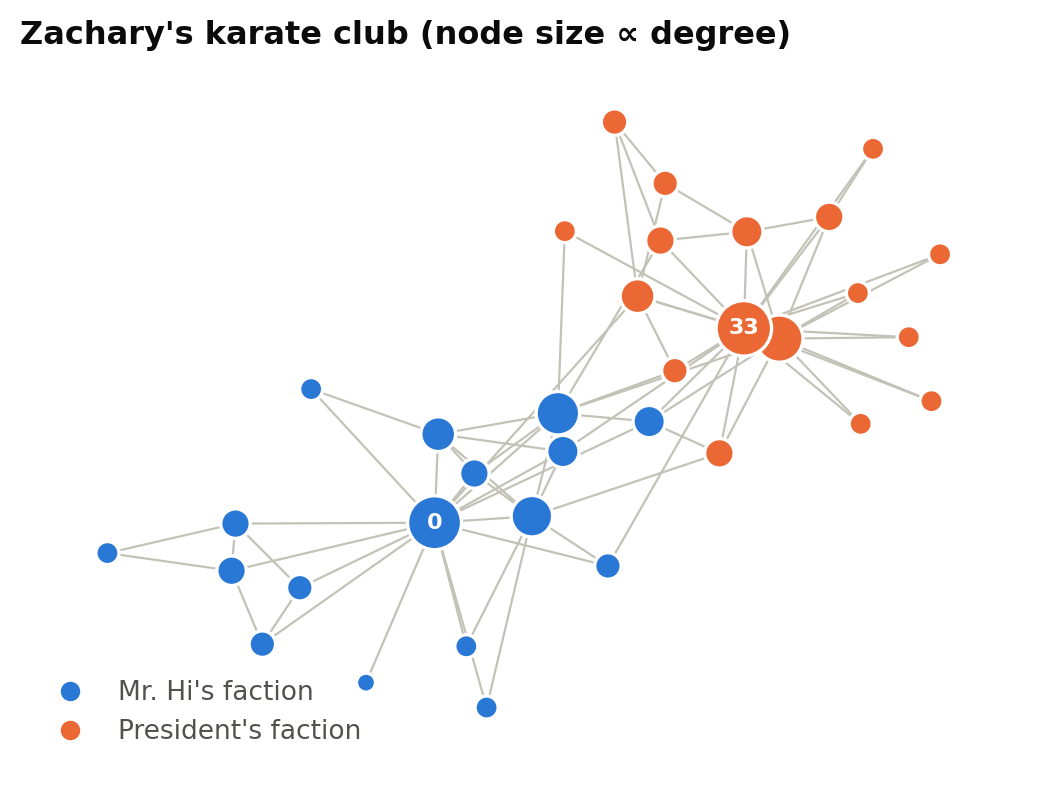

In [6]:
K = nx.karate_club_graph()
N, L = K.number_of_nodes(), K.number_of_edges()
k = degrees(K)

print(f"N = {N} nodes, L = {L} links")
print(f"<k> = 2L/N = {2*L/N:.2f}    (check, mean of the degrees: {k.mean():.2f})")
print(f"Largest degrees: node 33 -> k = {k[33]}, node 0 -> k = {k[0]};  smallest degree: {k.min()}")

pos = nx.spring_layout(K, seed=SEED)
faction = [BLUE if K.nodes[v]["club"] == "Mr. Hi" else ORANGE for v in K]
fig, ax = plt.subplots(figsize=(6.5, 4.6))
nx.draw_networkx_edges(K, pos, ax=ax, edge_color=LIGHT, width=0.8)
nx.draw_networkx_nodes(K, pos, ax=ax, node_size=25 + 22 * k, node_color=faction, edgecolors="white", linewidths=1.2)
nx.draw_networkx_labels(K, pos, labels={0: "0", 33: "33"}, font_size=8, font_color="white", font_weight="bold", ax=ax)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=BLUE, label="Mr. Hi's faction"),
                   Line2D([], [], marker="o", ls="", color=ORANGE, label="President's faction")], loc="lower left")
ax.set_title("Zachary's karate club (node size ∝ degree)"); ax.axis("off"); plt.show()

### I.2 The adjacency matrix (Section 2.4)
The matrix holds all of the information about the network. Simple linear algebra on $A$ gives back the quantities from Ch 2:
* $k_i = \sum_j A_{ij}$
* $(A^2)_{ij}$ = number of paths of length 2 from $i$ to $j$, i.e. the number of common neighbours
* $\mathrm{Tr}(A^3)/6$ = number of triangles

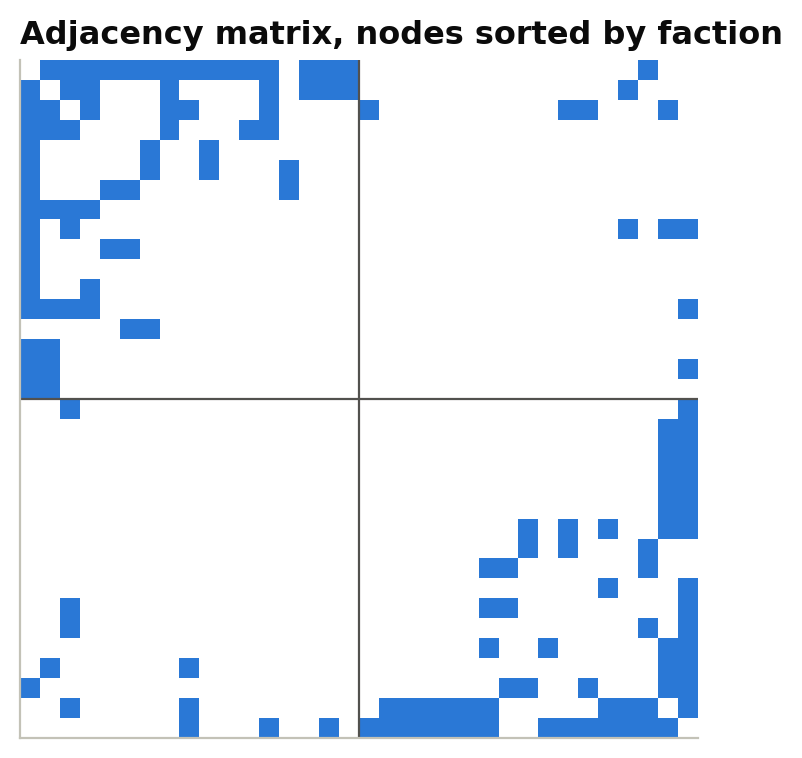

Symmetric (undirected network)?        True
Row sums equal the degrees?            True
L = (1/2) Σ A_ij                      = 78
(A²)_{0,33}  = common neighbours of 0 & 33 = 4   | networkx: 4
Tr(A³)/6     = number of triangles     = 45  | networkx: 45


In [7]:
order = sorted(K, key=lambda v: (K.nodes[v]["club"], v))        # group nodes by faction
A = nx.to_numpy_array(K, nodelist=order, weight=None, dtype=int)
n_hi = sum(K.nodes[v]["club"] == "Mr. Hi" for v in K)

fig, ax = plt.subplots(figsize=(4.4, 4.4))
ax.imshow(A, cmap=mpl.colors.ListedColormap(["white", BLUE]), interpolation="nearest")
for x in (n_hi - 0.5,):
    ax.axhline(x, color=INK2, lw=0.8); ax.axvline(x, color=INK2, lw=0.8)
ax.set_title("Adjacency matrix, nodes sorted by faction"); ax.grid(False)
ax.set_xticks([]); ax.set_yticks([]); plt.show()

i0, i33 = order.index(0), order.index(33)
A2, A3 = A @ A, np.linalg.matrix_power(A, 3)
print("Symmetric (undirected network)?       ", (A == A.T).all())
print("Row sums equal the degrees?           ", np.array_equal(A.sum(axis=1), [K.degree(v) for v in order]))
print("L = (1/2) Σ A_ij                      =", A.sum() // 2)
print("(A²)_{0,33}  = common neighbours of 0 & 33 =", A2[i0, i33], "  | networkx:", len(list(nx.common_neighbors(K, 0, 33))))
print("Tr(A³)/6     = number of triangles     =", np.trace(A3) // 6, " | networkx:", sum(nx.triangles(K).values()) // 3)

> **Look for:** the two dense diagonal blocks. Most links stay within a faction. This is a first glimpse of *community structure* (Ch 9), visible directly in $A$.

### I.3 Real networks are sparse (Section 2.5)
Our main real network for the session is the **science collaboration network** (co-authorship among scientists, from the book's Table 4.1).

Getting the data from https://networksciencebook.com/translations/en/resources/networks.zip  (~141 MB, one time only) ...
Done.
Science collaboration  [book data]
N = 23,133   L = 93,439   L_max = N(N-1)/2 = 267,556,278
Density L/L_max = 3.5e-04
<k> = 8.08, compared with N-1 = 23,132 for a complete graph
Dense matrix: 535 million entries; only 186,878 are non-zero (0.035%)


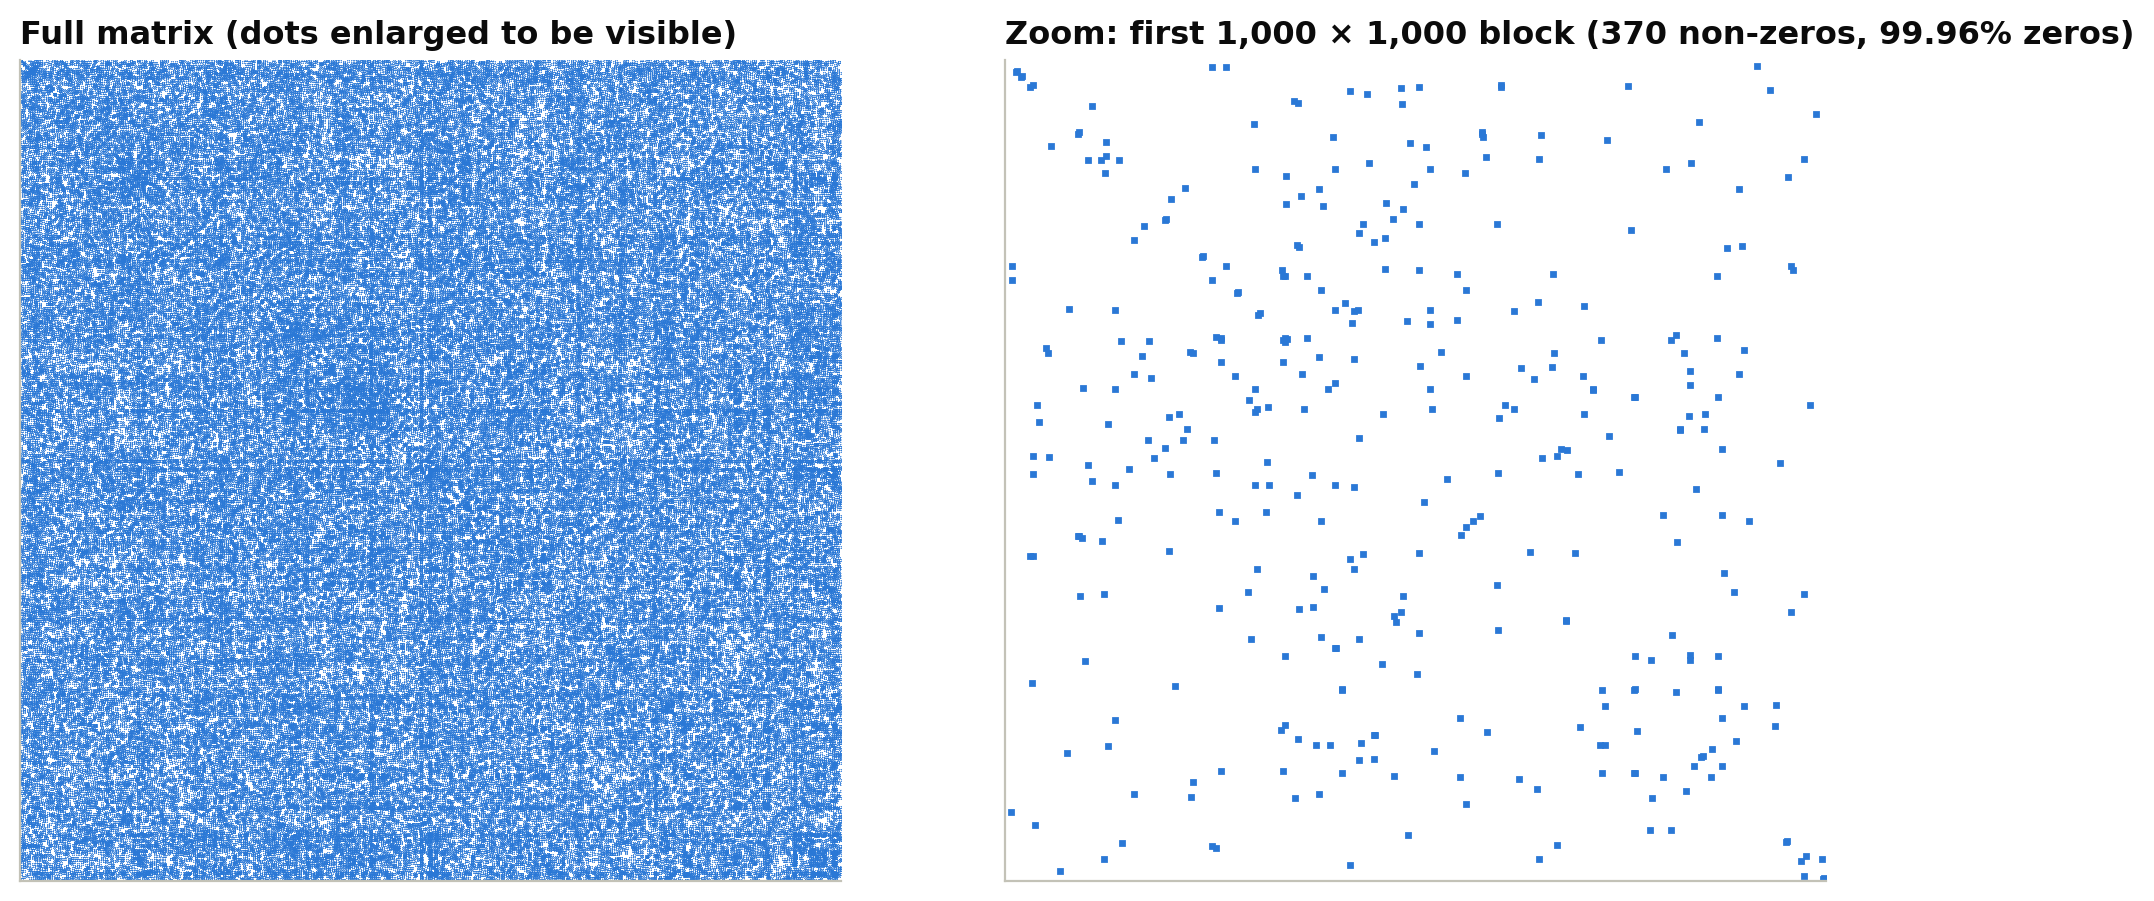

In [8]:
G = load_graph("collaboration")
N, L = G.number_of_nodes(), G.number_of_edges()
Lmax = N * (N - 1) // 2
print(f"{G.graph['name']}  [{G.graph['source']}]")
print(f"N = {N:,}   L = {L:,}   L_max = N(N-1)/2 = {Lmax:,}")
print(f"Density L/L_max = {L/Lmax:.1e}")
print(f"<k> = {2*L/N:.2f}, compared with N-1 = {N-1:,} for a complete graph")
print(f"Dense matrix: {N**2/1e6:,.0f} million entries; only {2*L:,} are non-zero ({2*L/N**2:.3%})")

A_c = nx.to_scipy_sparse_array(G, format="csr")
block = A_c[:1000][:, :1000]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
axes[0].spy(A_c, markersize=0.03, color=BLUE)
axes[0].set_title("Full matrix (dots enlarged to be visible)")
axes[1].spy(block, markersize=1.5, color=BLUE)
axes[1].set_title(f"Zoom: first 1,000 × 1,000 block ({block.nnz:,} non-zeros, {1 - block.nnz/1e6:.2%} zeros)")
for ax in axes:
    ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

> **Discuss:** Why do we store networks as **edge lists** or **sparse matrices**? How much memory would a dense matrix need for the WWW sample ($N \approx 3\times10^5$), or for Facebook ($N \approx 3\times10^9$)?

### I.4 Degree distributions (Section 2.3)

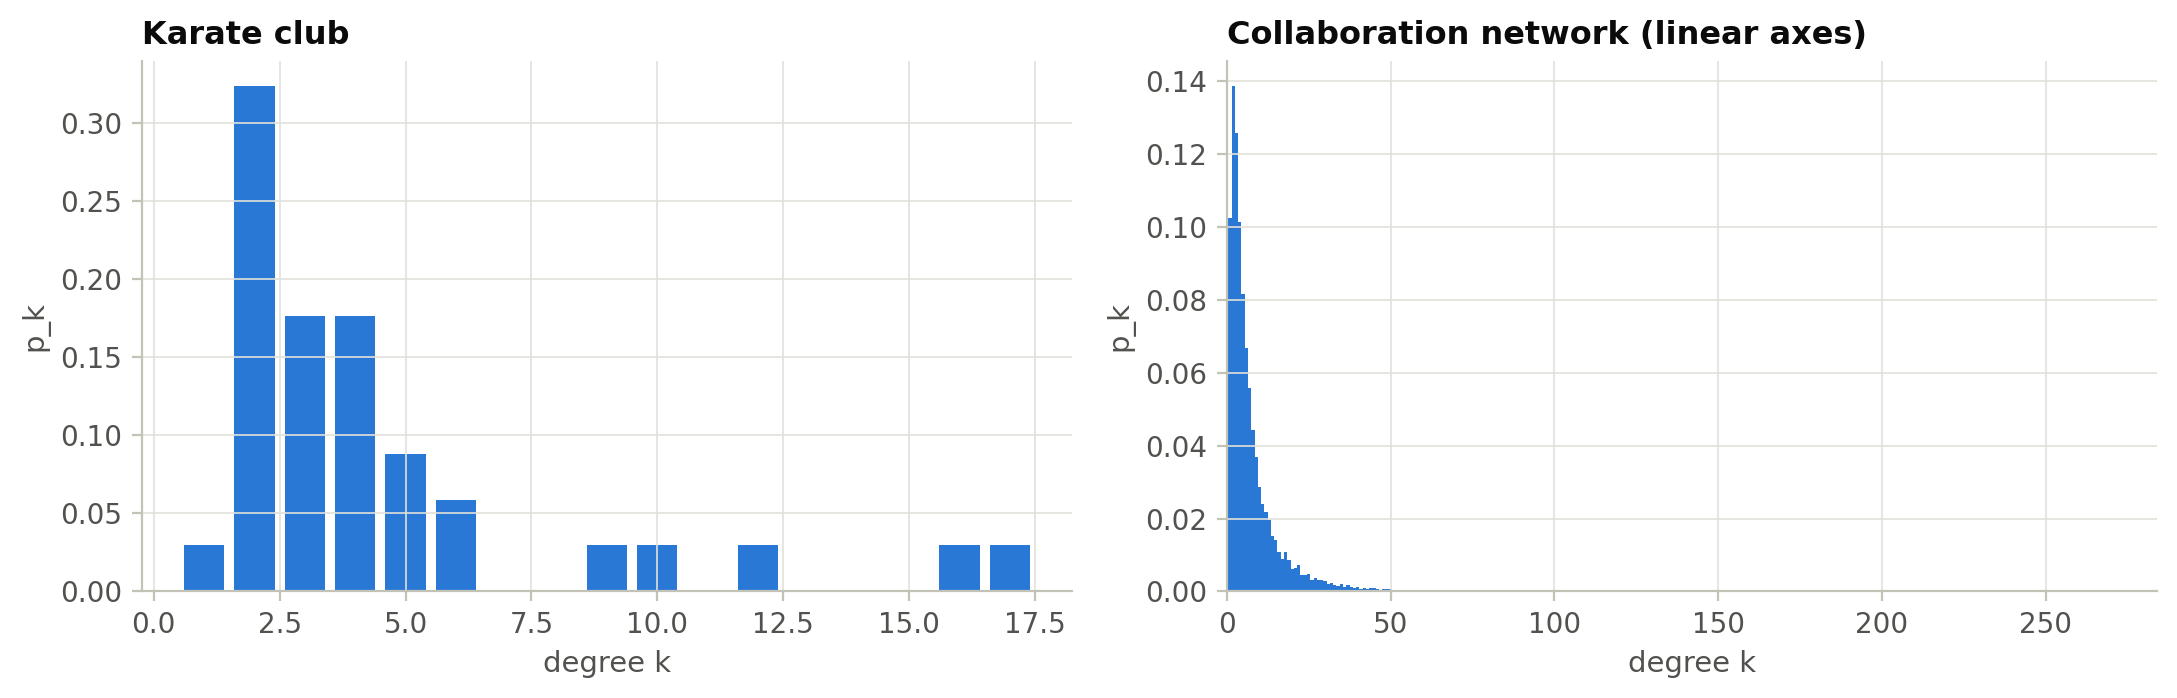

Collaboration: <k> = 8.08, median = 5, k_max = 279
Share of nodes with k <= 10: 78.3%;  nodes with k >= 100: 28


In [9]:
kc = degrees(G)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ks, pk = pk_linear(degrees(K))
axes[0].bar(ks, pk, width=0.8, color=BLUE)
axes[0].set(title="Karate club", xlabel="degree k", ylabel="p_k")
ks, pk = pk_linear(kc)
axes[1].bar(ks, pk, width=1.0, color=BLUE)
axes[1].set(title="Collaboration network (linear axes)", xlabel="degree k", ylabel="p_k", xlim=(0, kc.max() + 5))
plt.tight_layout(); plt.show()
print(f"Collaboration: <k> = {kc.mean():.2f}, median = {np.median(kc):.0f}, k_max = {kc.max()}")
print(f"Share of nodes with k <= 10: {np.mean(kc <= 10):.1%};  nodes with k >= 100: {(kc >= 100).sum()}")

> **Look for:** on linear axes the collaboration distribution appears to end at about $k\approx 50$. Yet the largest node has $k_{\max}$ in the hundreds. These rare, highly connected nodes are invisible here. Part III shows how to plot them properly.

### I.5 Paths and distances (Section 2.8)

Diameter d_max = 5;  average distance <d> = 2.41
A longest shortest path: 14 -> 16 = [14, 32, 2, 0, 5, 16] (length 5); there are 14 shortest paths between them


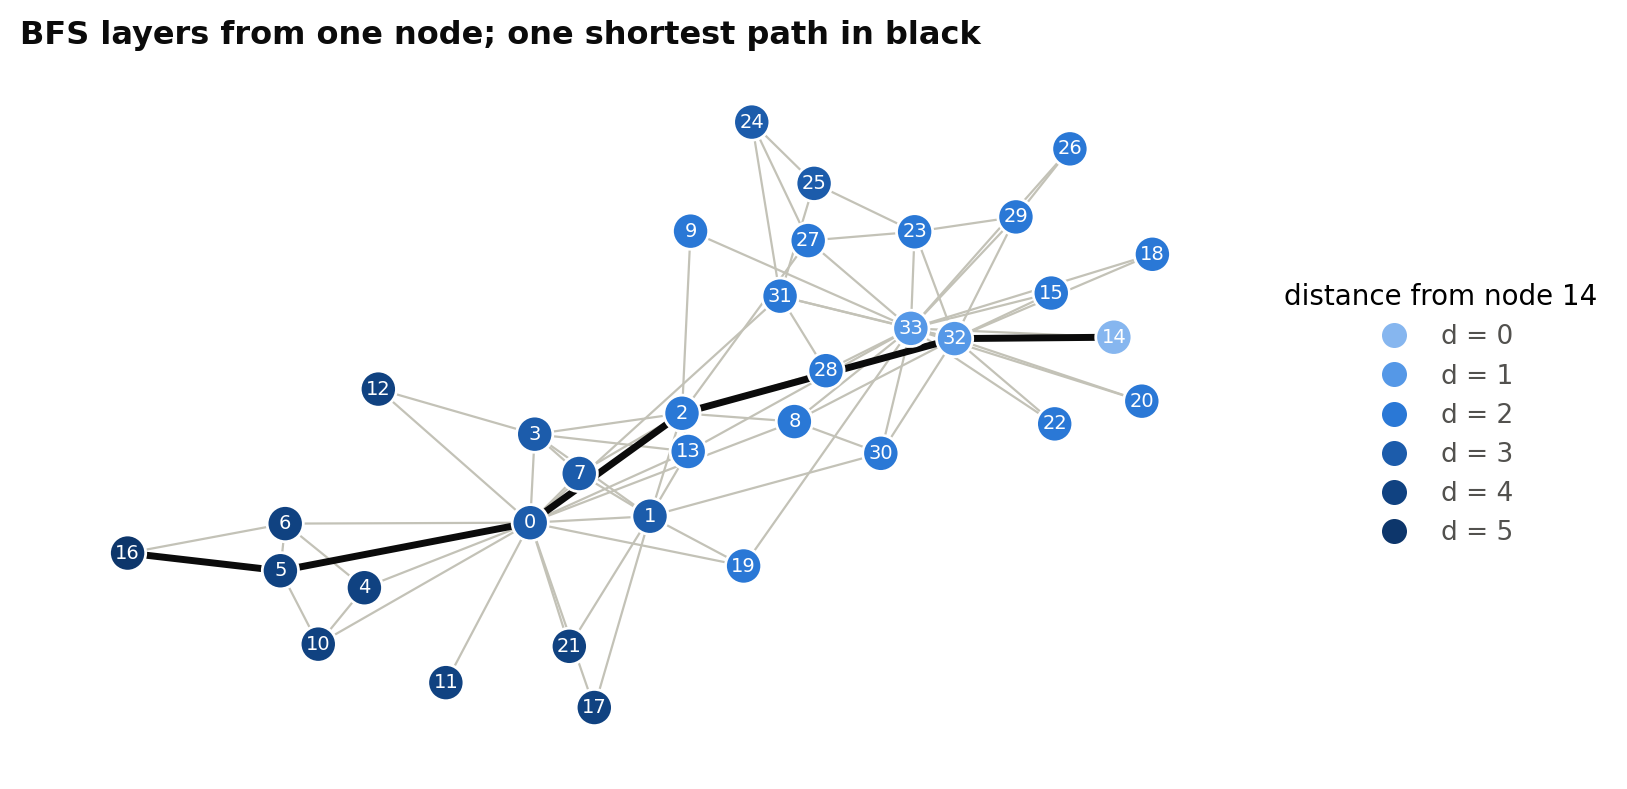

In [10]:
spl = dict(nx.all_pairs_shortest_path_length(K))
s, t = max(((u, v) for u in K for v in K), key=lambda uv: spl[uv[0]][uv[1]])
path = nx.shortest_path(K, s, t)
print(f"Diameter d_max = {nx.diameter(K)};  average distance <d> = {nx.average_shortest_path_length(K):.2f}")
print(f"A longest shortest path: {s} -> {t} = {path} (length {len(path) - 1}); "
      f"there are {len(list(nx.all_shortest_paths(K, s, t)))} shortest paths between them")

# Breadth-first search from s: colour = distance from s
dist = nx.single_source_shortest_path_length(K, s)
fig, ax = plt.subplots(figsize=(8, 4.6))
nx.draw_networkx_edges(K, pos, ax=ax, edge_color=LIGHT, width=0.8)
nx.draw_networkx_edges(K, pos, ax=ax, edgelist=list(zip(path, path[1:])), edge_color=INK, width=2.5)
nx.draw_networkx_nodes(K, pos, ax=ax, node_size=170, node_color=[BLUES[dist[v]] for v in K], edgecolors="white")
nx.draw_networkx_labels(K, pos, font_size=7, font_color="white", ax=ax)
ax.legend(handles=[Line2D([], [], marker="o", ls="", ms=8, color=BLUES[d], label=f"d = {d}") for d in sorted(set(dist.values()))],
          title=f"distance from node {s}", loc="center left", bbox_to_anchor=(1.0, 0.5))
ax.set_title("BFS layers from one node; one shortest path in black"); ax.axis("off"); plt.show()

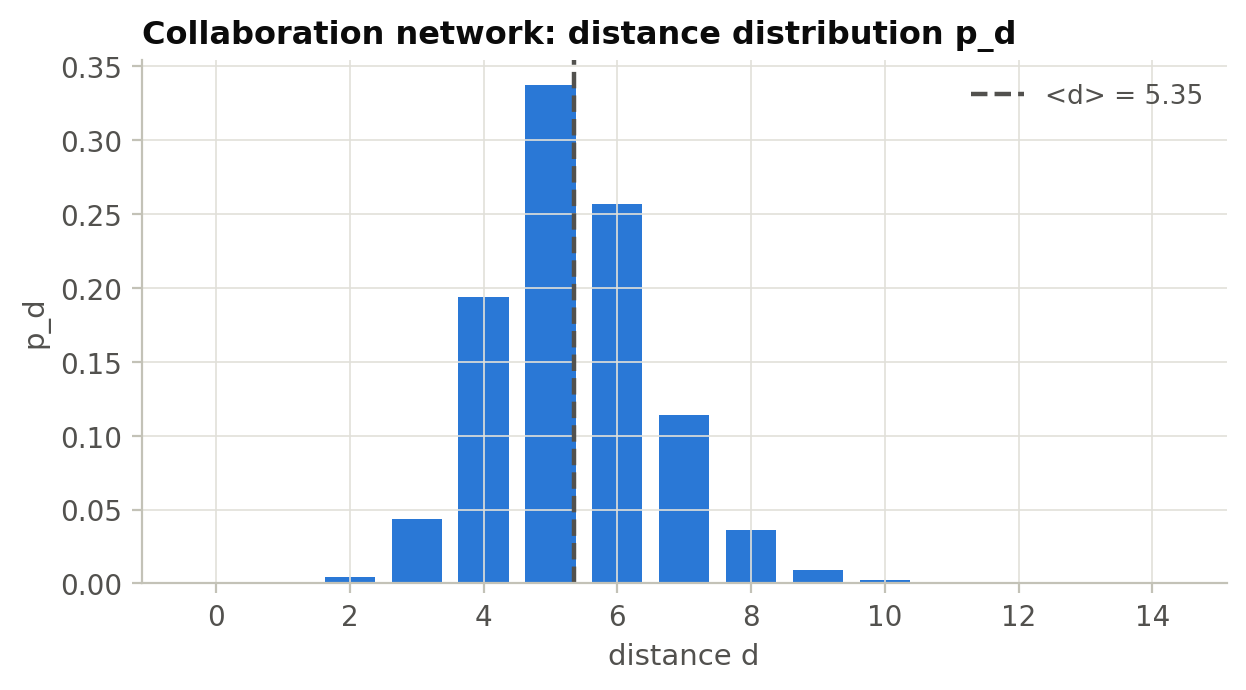

Largest distance observed: 14;  share of pairs within 6 steps: 83.8%


In [11]:
# Distances in the collaboration network: exact all-pairs is ~2.7e8 BFS steps, so we sample sources.
d_collab = distance_sample(G, n_sources=300)          # sources drawn from the giant component
pd_ = np.bincount(d_collab) / d_collab.size
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(np.arange(pd_.size), pd_, width=0.75, color=BLUE)
ax.axvline(d_collab.mean(), **THEORY, label=f"<d> = {d_collab.mean():.2f}")
ax.set(title="Collaboration network: distance distribution p_d", xlabel="distance d", ylabel="p_d"); ax.legend()
plt.show()
print(f"Largest distance observed: {d_collab.max()};  share of pairs within 6 steps: {np.mean(d_collab <= 6):.1%}")

### I.6 Connectedness (Section 2.9)

567 connected components
Giant component: 21,363 nodes (92.3%);  second largest: 21 nodes


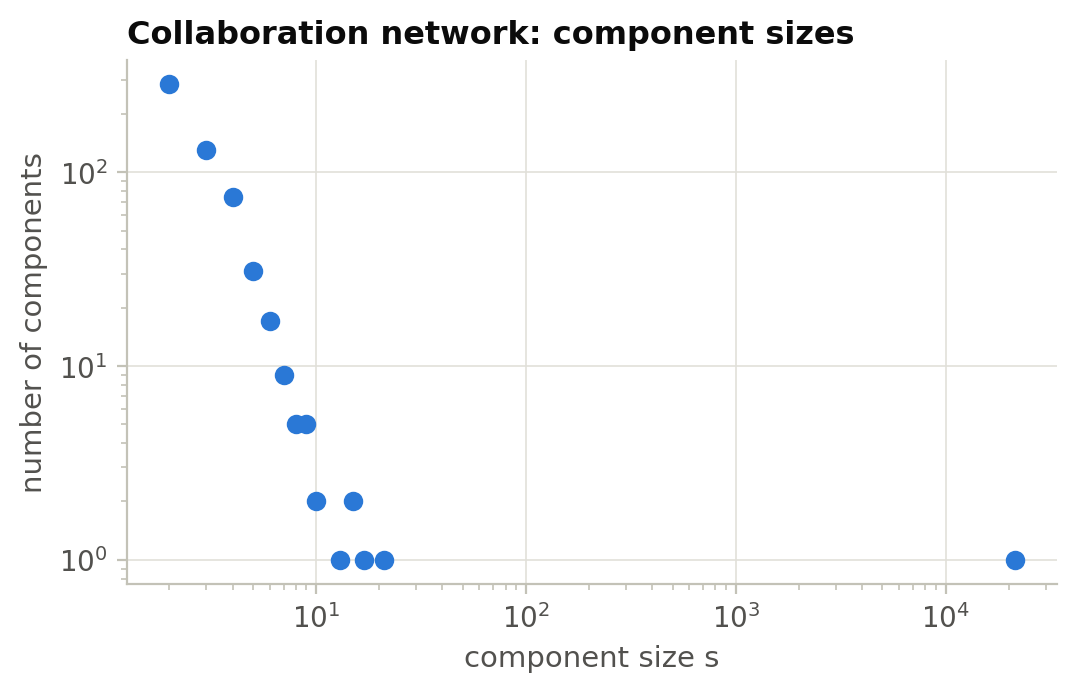

In [12]:
sizes = np.array(sorted(map(len, nx.connected_components(G)), reverse=True))
print(f"{sizes.size:,} connected components")
print(f"Giant component: {sizes[0]:,} nodes ({sizes[0]/N:.1%});  second largest: {sizes[1] if sizes.size > 1 else 0} nodes")
s_vals, n_s = np.unique(sizes, return_counts=True)
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.loglog(s_vals, n_s, "o", color=BLUE)
ax.set(title="Collaboration network: component sizes", xlabel="component size s", ylabel="number of components")
plt.show()

> **Look for:** one giant component and a dust of tiny ones, with nothing in between. Ch 3 explains why this is what a network with $\langle k\rangle > 1$ is expected to look like.

### I.7 Clustering (Section 2.10)
There are two common summaries of clustering:
* the **average local clustering** $\langle C\rangle = \frac1N\sum_i C_i$ (book, Eq. 2.16);
* the **global clustering** $C_\Delta = \dfrac{3\times\#\text{triangles}}{\#\text{connected triples}}$ (`nx.transitivity`).

They answer different questions and can differ substantially.

Karate club:   C_0 = 0.150 (k=16),  C_33 = 0.110 (k=17),  <C> = 0.571,  C_Δ = 0.256
Collaboration: <C> = 0.633,  C_Δ = 0.264


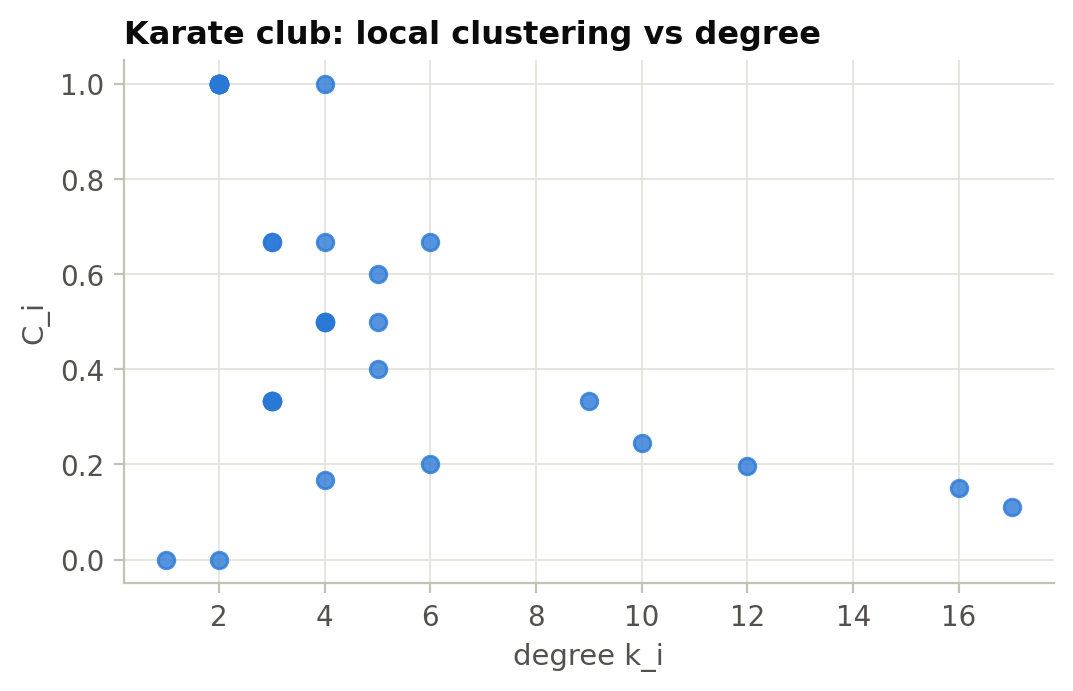

In [13]:
CK = nx.clustering(K)
print("Karate club:   C_0 = {:.3f} (k={}),  C_33 = {:.3f} (k={}),  <C> = {:.3f},  C_Δ = {:.3f}".format(
      CK[0], K.degree(0), CK[33], K.degree(33), nx.average_clustering(K), nx.transitivity(K)))
print("Collaboration: <C> = {:.3f},  C_Δ = {:.3f}".format(nx.average_clustering(G), nx.transitivity(G)))

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(degrees(K), [CK[v] for v in K], "o", color=BLUE, alpha=0.8)
ax.set(title="Karate club: local clustering vs degree", xlabel="degree k_i", ylabel="C_i")
plt.show()

> **Look for:** the hubs (nodes 0 and 33) have *low* $C_i$, while low-degree nodes often sit in closed triangles. We return to this $C(k)$ trend in Part II.
>
> **Discuss:** Why is $\langle C\rangle$ larger than $C_\Delta$ in the collaboration network? (Hint: which nodes dominate each average?)

### I.8 Bipartite and weighted networks (Sections 2.6–2.7) *(optional)*
Davis' *Southern Women* data: 18 women and the 14 social events they attended. Projecting onto the women gives a **weighted** network, where the weight of a link is the number of events two women attended together.

Bipartite? True | 18 women, 14 events, 89 attendances
Projection: 18 nodes, 139 links (density 0.91, much denser than the bipartite graph)


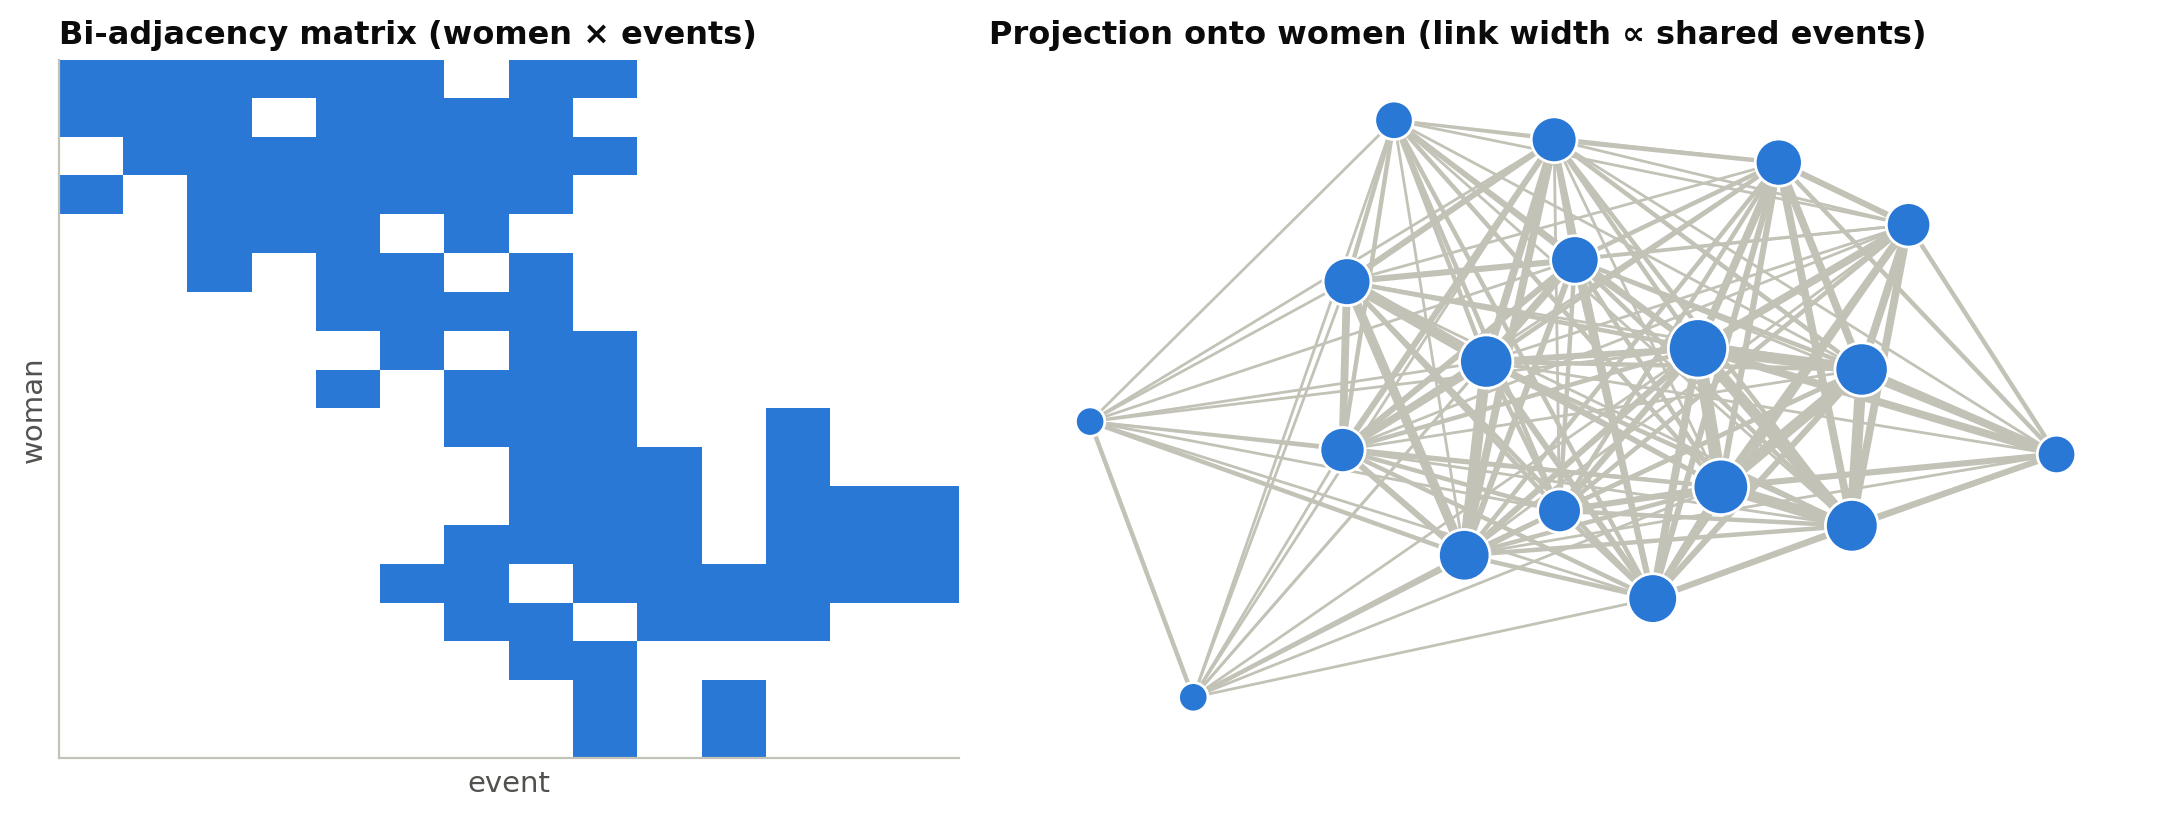

In [14]:
B = nx.davis_southern_women_graph()
women, events = B.graph["top"], B.graph["bottom"]
W = nx.bipartite.weighted_projected_graph(B, women)
print(f"Bipartite? {nx.is_bipartite(B)} | {len(women)} women, {len(events)} events, {B.number_of_edges()} attendances")
print(f"Projection: {W.number_of_nodes()} nodes, {W.number_of_edges()} links "
      f"(density {nx.density(W):.2f}, much denser than the bipartite graph)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})
M = nx.bipartite.biadjacency_matrix(B, row_order=women, column_order=events).toarray()
axes[0].imshow(M, cmap=mpl.colors.ListedColormap(["white", BLUE]), aspect="auto")
axes[0].set(title="Bi-adjacency matrix (women × events)", xlabel="event", ylabel="woman"); axes[0].grid(False)
axes[0].set_xticks([]); axes[0].set_yticks([])
wpos = nx.spring_layout(W, seed=SEED, weight="weight")
w = np.array([W[u][v]["weight"] for u, v in W.edges()])
nx.draw_networkx_edges(W, wpos, ax=axes[1], width=0.4 + 0.6 * w, edge_color=LIGHT)
nx.draw_networkx_nodes(W, wpos, ax=axes[1], node_size=[8 * W.degree(v, weight="weight") for v in W],
                       node_color=BLUE, edgecolors="white")
axes[1].set_title("Projection onto women (link width ∝ shared events)"); axes[1].axis("off")
plt.tight_layout(); plt.show()

---
## Part II: Random networks, the null model (Ch 3) *(about 35 min)*

In the Erdős–Rényi model $G(N,p)$, each of the $N(N-1)/2$ pairs is linked independently with probability $p$.

| Quantity | Prediction | Book |
|---|---|---|
| Number of links | $\langle L\rangle = p\frac{N(N-1)}{2}$, binomially distributed | 3.3 |
| Average degree | $\langle k\rangle = p(N-1)$ | 3.3 |
| Degree distribution | binomial, which becomes Poisson $p_k = e^{-\langle k\rangle}\frac{\langle k\rangle^k}{k!}$ for $\langle k\rangle\ll N$ | 3.4 |
| Giant component | appears at $\langle k\rangle = 1$; $S = 1-e^{-\langle k\rangle S}$ | 3.6 |
| Fully connected | when $\langle k\rangle > \ln N$ | 3.6 |
| Average distance | $\langle d\rangle \approx \dfrac{\ln N}{\ln\langle k\rangle}$ | 3.8 |
| Clustering | $C = p = \langle k\rangle/N$, independent of $k$ | 3.9 |

### II.1 The number of links is a random variable (Section 3.3)

<L>: theory p·N(N-1)/2 = 995.0   simulated = 996.1
σ_L: theory √(L_max p(1-p)) = 30.7   simulated = 30.9


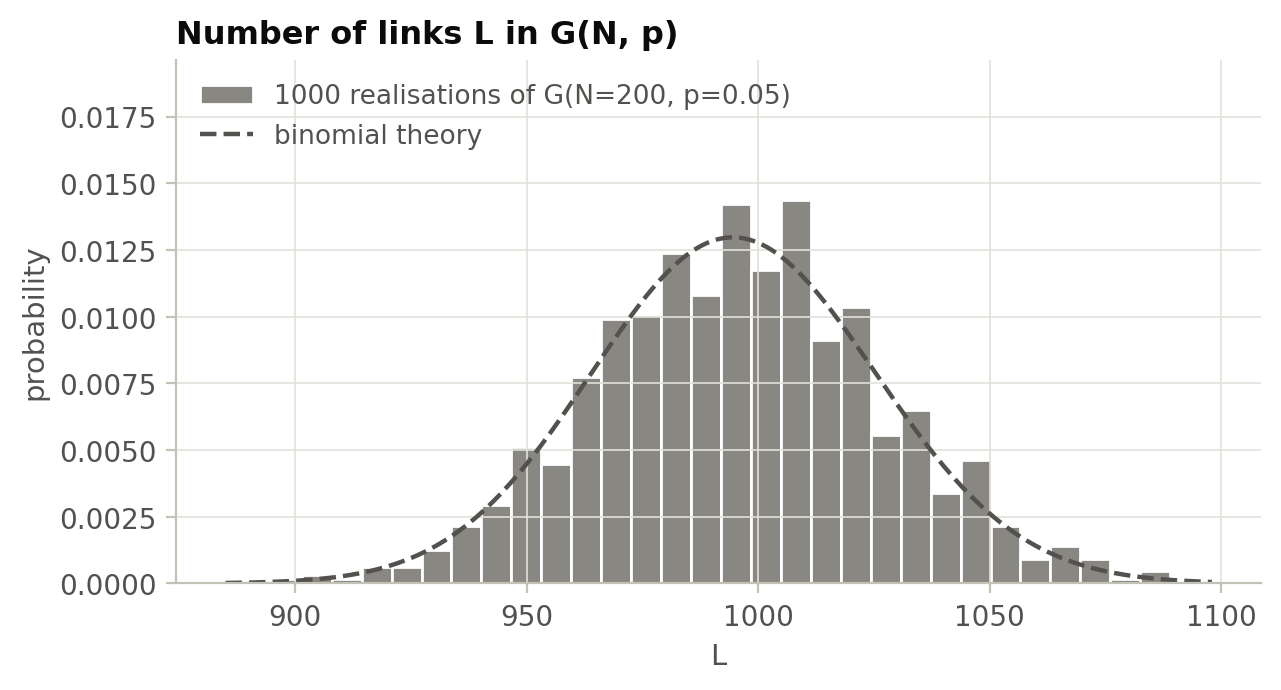

In [15]:
N, p, R = 200, 0.05, 1000
Ls = np.array([nx.gnp_random_graph(N, p, seed=s).number_of_edges() for s in range(R)])
Lmax = N * (N - 1) // 2
print(f"<L>: theory p·N(N-1)/2 = {p*Lmax:.1f}   simulated = {Ls.mean():.1f}")
print(f"σ_L: theory √(L_max p(1-p)) = {np.sqrt(Lmax*p*(1-p)):.1f}   simulated = {Ls.std():.1f}")

x = np.arange(Ls.min() - 10, Ls.max() + 10)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(Ls, bins=30, density=True, color=MUTED, edgecolor="white", label=f"{R} realisations of G(N={N}, p={p})")
ax.plot(x, stats.binom.pmf(x, Lmax, p), **THEORY, label="binomial theory")
ax.set_ylim(top=ax.get_ylim()[1] * 1.3)
ax.set(title="Number of links L in G(N, p)", xlabel="L", ylabel="probability"); ax.legend(loc="upper left"); plt.show()

### II.2 Degree distribution: binomial → Poisson (Section 3.4)
For fixed $\langle k\rangle$, the shape of $p_k$ **does not depend on $N$**. This is one of the defining properties of random networks.

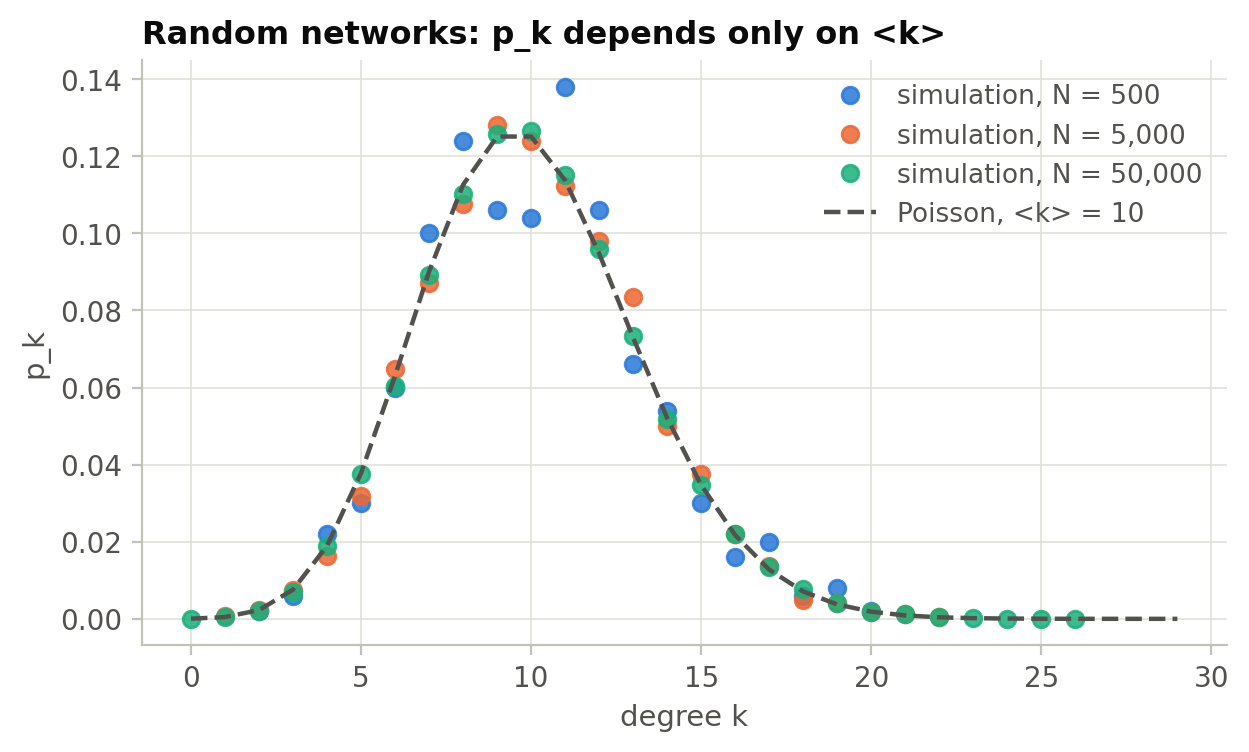

Poisson: σ_k = √<k> = 3.16, so nearly all nodes have k = 10 ± 9 (3σ)


In [16]:
avg_k = 10
fig, ax = plt.subplots(figsize=(7, 3.8))
for N, c in zip([500, 5_000, 50_000], [BLUE, ORANGE, AQUA]):
    ks, pk = pk_linear(degrees(nx.fast_gnp_random_graph(N, avg_k / (N - 1), seed=SEED)))
    ax.plot(ks, pk, "o", color=c, ms=6, alpha=0.85, label=f"simulation, N = {N:,}")
kk = np.arange(0, 30)
ax.plot(kk, stats.poisson.pmf(kk, avg_k), **THEORY, label="Poisson, <k> = 10")
ax.set(title="Random networks: p_k depends only on <k>", xlabel="degree k", ylabel="p_k"); ax.legend(); plt.show()
print(f"Poisson: σ_k = √<k> = {np.sqrt(avg_k):.2f}, so nearly all nodes have k = {avg_k} ± {3*np.sqrt(avg_k):.0f} (3σ)")

### II.3 Real networks are not Poisson (Section 3.5)
How many highly connected nodes would a random network with the same $N$ and $\langle k\rangle$ as the collaboration network contain?

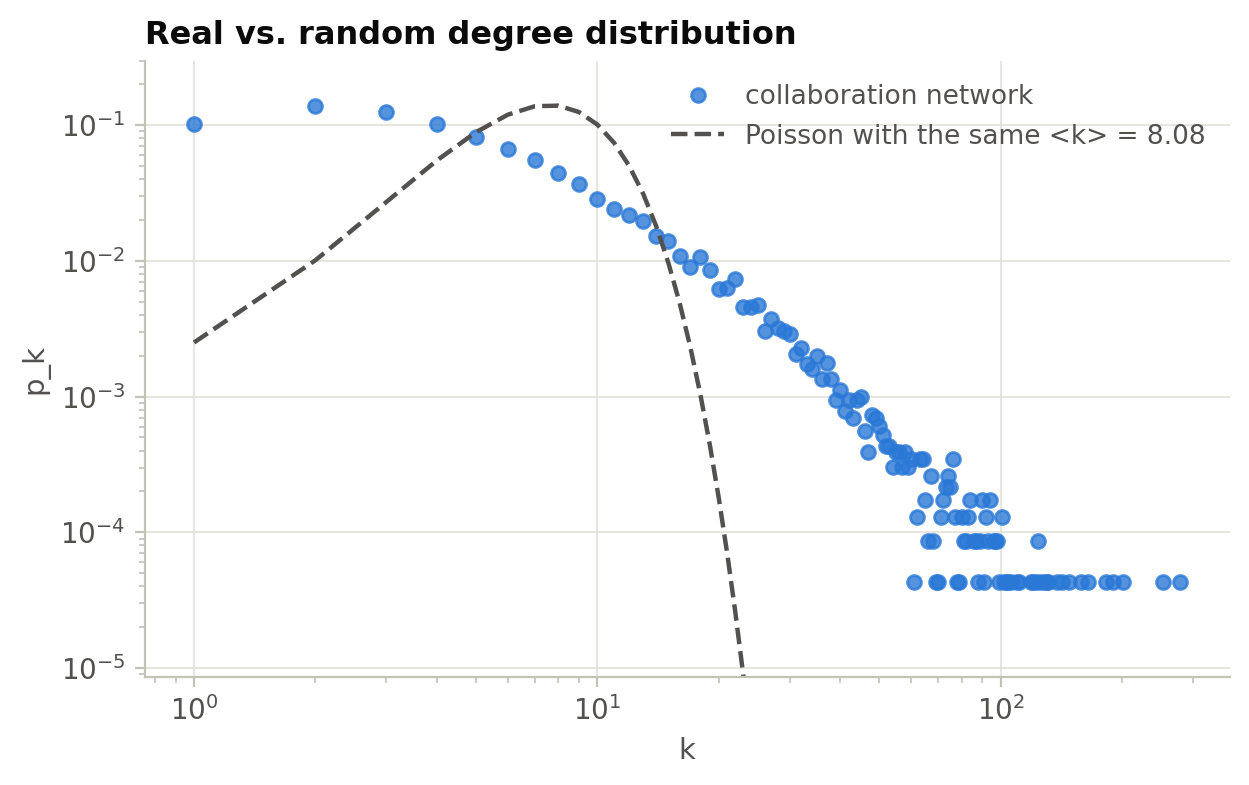

Largest degree expected in a random network:  k_max ≈ 21
Largest degree observed:                       k_max = 279
Nodes with k >= 50:  observed 244,  expected under Poisson 6.5e-19
Expected number of nodes with k >= 279 under Poisson: 10^-309


In [17]:
kc = degrees(G); N, avg = kc.size, kc.mean()
ks, pk = pk_linear(kc)
kk = np.arange(1, kc.max() + 1)

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(ks, pk, "o", color=BLUE, ms=5, alpha=0.8, label="collaboration network")
ax.loglog(kk, stats.poisson.pmf(kk, avg), **THEORY, label=f"Poisson with the same <k> = {avg:.2f}")
ax.set(ylim=(0.2 / N, 0.3), title="Real vs. random degree distribution", xlabel="k", ylabel="p_k"); ax.legend(); plt.show()

k_max_poisson = stats.poisson.isf(1 / N, avg)          # N·P(K > k_max) = 1   (Advanced Topic 3.B)
print(f"Largest degree expected in a random network:  k_max ≈ {k_max_poisson:.0f}")
print(f"Largest degree observed:                       k_max = {kc.max()}")
print(f"Nodes with k >= 50:  observed {(kc >= 50).sum()},  expected under Poisson {N*stats.poisson.sf(49, avg):.1e}")
log_tail = scipy.special.logsumexp(stats.poisson.logpmf(np.arange(kc.max(), kc.max() + 2000), avg))   # ln P(K >= k_max)
print(f"Expected number of nodes with k >= {kc.max()} under Poisson: 10^{(np.log(N) + log_tail) / np.log(10):.0f}")

> **Discuss:** A random-network model predicts no node with more than about 20 collaborators, yet the data contain dozens of scientists with more than 100. Which processes could produce these hubs? (Keep this question in mind for Ch 5.)

### II.4 The evolution of a random network (Section 3.6)
We increase $\langle k\rangle$ and track the largest component $N_G$. The theory (Advanced Topic 3.C) gives the fraction $S = N_G/N$ as the solution of $S = 1 - e^{-\langle k\rangle S}$.

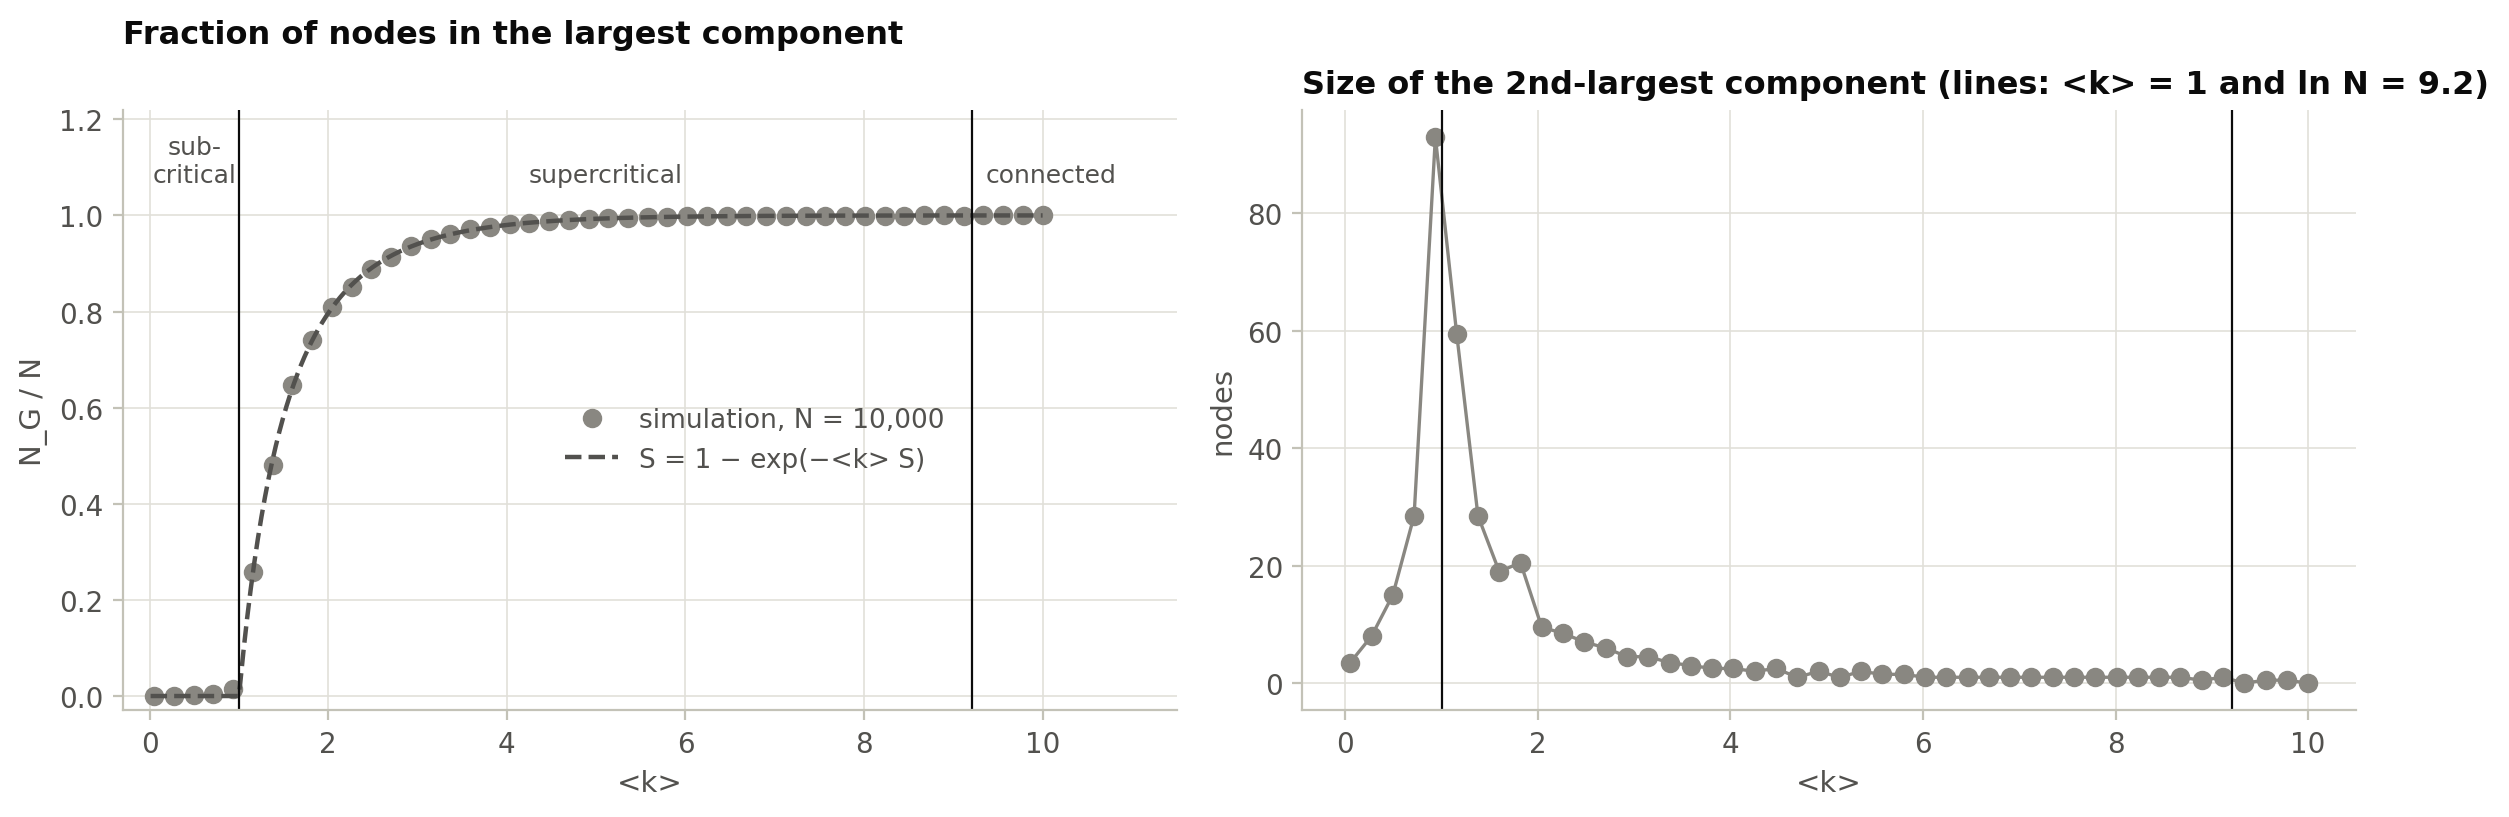

In [18]:
N, reps = 10_000, 2
avg_ks = np.linspace(0.05, 10, 46)
S1, S2 = np.zeros_like(avg_ks), np.zeros_like(avg_ks)
for i, c in enumerate(avg_ks):
    for r in range(reps):
        sz = sorted(map(len, nx.connected_components(nx.fast_gnp_random_graph(N, c / (N - 1), seed=1000 * i + r))), reverse=True)
        S1[i] += sz[0] / reps
        S2[i] += (sz[1] if len(sz) > 1 else 0) / reps

c_th = np.linspace(0.01, 10, 500); S_th = np.ones_like(c_th)
for _ in range(3000):
    S_th = 1 - np.exp(-c_th * S_th)                      # fixed-point iteration

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(avg_ks, S1 / N, "o", color=MUTED, label=f"simulation, N = {N:,}")
axes[0].plot(c_th, S_th, **THEORY, label="S = 1 − exp(−<k> S)")
axes[1].plot(avg_ks, S2, "o-", color=MUTED, lw=1.2)
for ax in axes:
    ax.axvline(1, color=INK, lw=0.8); ax.axvline(np.log(N), color=INK, lw=0.8)
    ax.set_xlabel("<k>")
for x_, txt, ha in [(0.5, "sub-\ncritical", "center"), ((1 + np.log(N)) / 2, "supercritical", "center"), (np.log(N) + 0.15, "connected", "left")]:
    axes[0].text(x_, 1.06, txt, ha=ha, va="bottom", color=INK2, fontsize=9)
axes[0].set_xlim(-0.3, 11.5)
axes[0].set_ylim(-0.03, 1.22)
axes[0].set_title("Fraction of nodes in the largest component", pad=24)
axes[0].set_ylabel("N_G / N"); axes[0].legend(loc="center", bbox_to_anchor=(0.6, 0.45))
axes[1].set(title=f"Size of the 2nd-largest component (lines: <k> = 1 and ln N = {np.log(N):.1f})", ylabel="nodes")
plt.tight_layout(); plt.show()

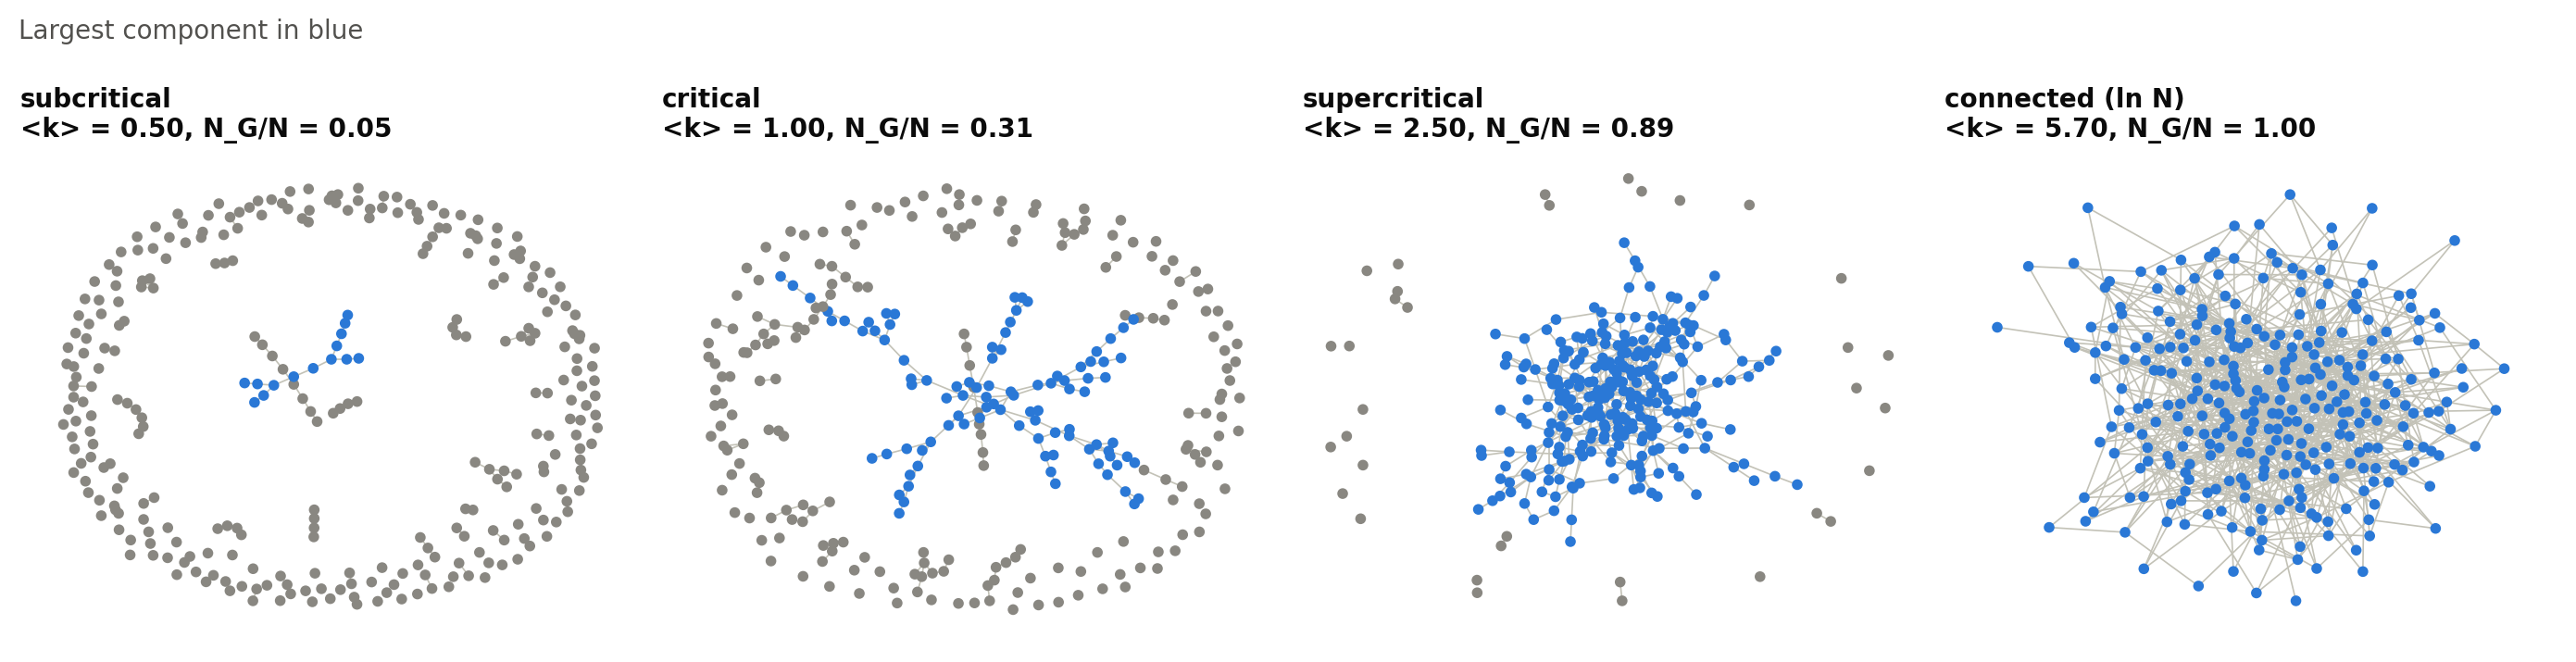

In [19]:
N = 300
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, (c, label) in zip(axes, [(0.5, "subcritical"), (1.0, "critical"), (2.5, "supercritical"), (np.log(N), "connected (ln N)")]):
    g = nx.fast_gnp_random_graph(N, c / (N - 1), seed=7)
    gc = max(nx.connected_components(g), key=len)
    gpos = nx.spring_layout(g, seed=SEED, k=1.5 / np.sqrt(N))
    nx.draw_networkx_edges(g, gpos, ax=ax, edge_color=LIGHT, width=0.6)
    nx.draw_networkx_nodes(g, gpos, ax=ax, node_size=10, node_color=[BLUE if v in gc else MUTED for v in g])
    ax.set_title(f"{label}\n<k> = {c:.2f}, N_G/N = {len(gc)/N:.2f}", fontsize=10); ax.axis("off")
fig.suptitle("Largest component in blue", x=0.01, ha="left", color=INK2, fontsize=10)
plt.tight_layout(); plt.show()

> **Look for:** (left) the giant component appears *continuously but abruptly* at $\langle k\rangle=1$; this is a phase transition. (Right) the 2nd-largest component peaks exactly at the critical point, a finite-size sign of the transition.

**Optional: how the largest component scales with $N$ (Advanced Topic 3.D).** Below the threshold $N_G\sim\ln N$; at the threshold $N_G\sim N^{2/3}$; above it $N_G\sim N$.

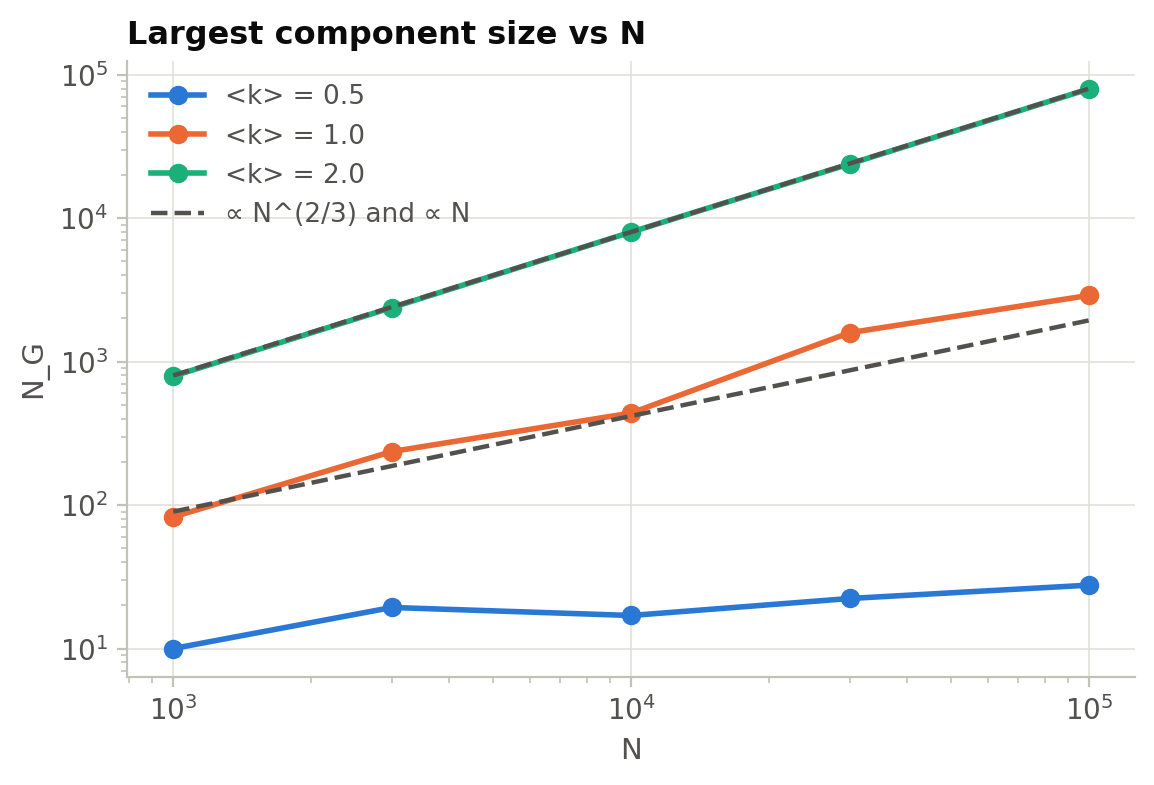

In [20]:
Ns = np.array([1_000, 3_000, 10_000, 30_000, 100_000])
fig, ax = plt.subplots(figsize=(6.5, 4))
for c, col in zip([0.5, 1.0, 2.0], [BLUE, ORANGE, AQUA]):
    NG = [np.mean([max(map(len, nx.connected_components(nx.fast_gnp_random_graph(n, c / (n - 1), seed=r)))) for r in range(3)]) for n in Ns]
    ax.loglog(Ns, NG, "o-", color=col, label=f"<k> = {c}")
ax.loglog(Ns, 0.9 * Ns**(2/3), **THEORY, label="∝ N^(2/3) and ∝ N")
ax.loglog(Ns, 0.8 * Ns, **THEORY)
ax.set(title="Largest component size vs N", xlabel="N", ylabel="N_G"); ax.legend(); plt.show()

### II.5 Real networks are supercritical (Section 3.7)
Where do the real networks sit on the phase diagram above?

In [21]:
rows = []
for name, (desc, _) in DATASETS.items():
    e, N, source = load_edges(name)
    A_ = sp.coo_matrix((np.ones(len(e)), (e[:, 0], e[:, 1])), shape=(N, N)).tocsr()
    _, labels = connected_components(A_, directed=False)
    avg = 2 * len(e) / N
    rows.append({"network": desc, "N": N, "L": len(e), "<k>": avg, "ln N": np.log(N),
                 "ER regime": "connected" if avg > np.log(N) else ("supercritical" if avg > 1 else "subcritical"),
                 "observed N_G/N": np.bincount(labels).max() / N, "data": source})
supercrit = pd.DataFrame(rows).set_index("network")
supercrit

,N,L,<k>,ln N,ER regime,observed N_G/N,data
network,,,,,,,
E. coli metabolism,1039,4741,9.126,6.946,connected,1.000,book data
Protein interactions (yeast),2018,2705,2.681,7.610,supercritical,0.816,book data
US power grid,4941,6594,2.669,8.505,supercritical,1.000,book data
Science collaboration,23133,93439,8.078,10.049,supercritical,0.923,book data
Mobile phone calls,36595,56853,3.107,10.508,supercritical,0.831,book data
Email,57194,92442,3.233,10.954,supercritical,0.989,book data
Internet (routers),192244,609066,6.336,12.167,supercritical,0.993,book data
WWW (nd.edu pages),325729,1090108,6.693,12.694,supercritical,1.000,book data


> **Look for:** every network has $\langle k\rangle > 1$, so all of them are supercritical. Most also have $\langle k\rangle < \ln N$, so a random network would leave many nodes outside the giant component. Some real networks, like the power grid, are nevertheless (almost) fully connected.
>
> **Discuss:** Why might a power grid be fully connected even though $\langle k\rangle < \ln N$? (Real networks are *designed* or *grow*; they are not wired at random.)

### II.6 Small worlds (Section 3.8)

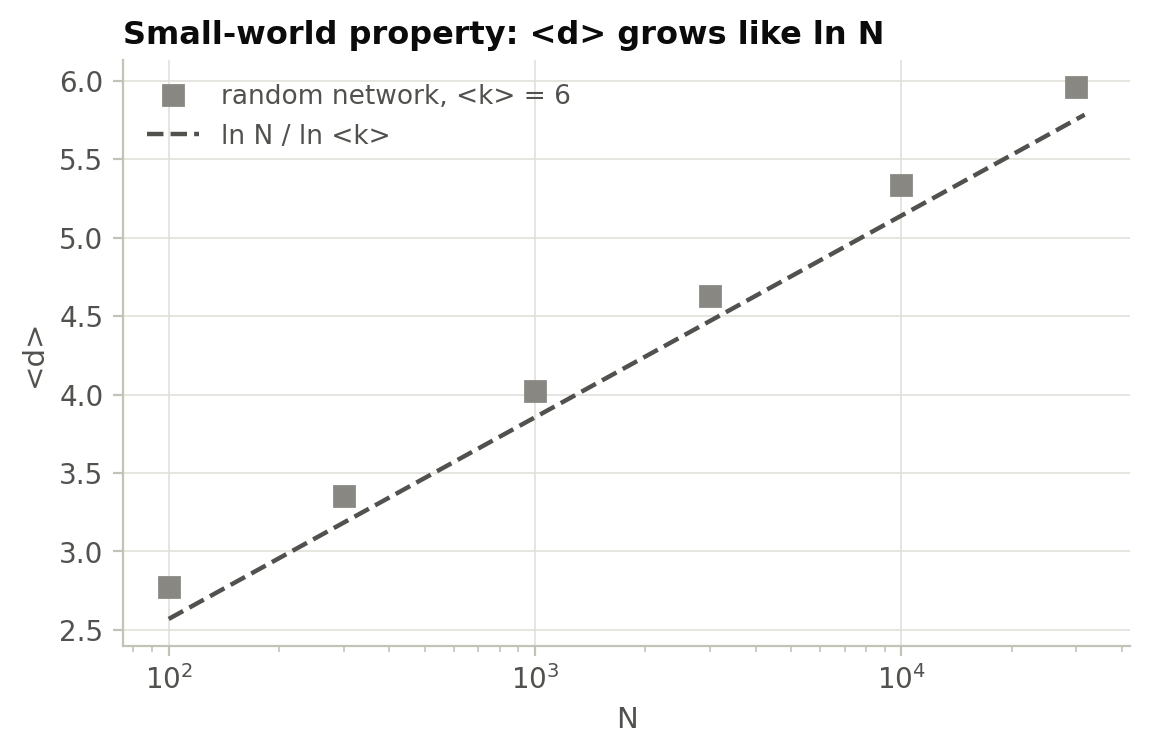

Collaboration network: observed <d> = 5.35;  ER prediction ln N/ln<k> = 4.81
Six degrees: N = 8.2e9 people with <k> ≈ 1000 acquaintances gives ln N/ln<k> = 3.3


In [22]:
avg_k = 6
Ns = np.array([100, 300, 1_000, 3_000, 10_000, 30_000])
d_er = [distance_sample(nx.fast_gnp_random_graph(n, avg_k / (n - 1), seed=SEED), 200).mean() for n in Ns]

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.semilogx(Ns, d_er, "s", color=MUTED, ms=7, label=f"random network, <k> = {avg_k}")
nn = np.logspace(2, 4.5, 50)
ax.semilogx(nn, np.log(nn) / np.log(avg_k), **THEORY, label="ln N / ln <k>")
ax.set(title="Small-world property: <d> grows like ln N", xlabel="N", ylabel="<d>"); ax.legend(); plt.show()

kc = degrees(G)
print(f"Collaboration network: observed <d> = {d_collab.mean():.2f};  ER prediction ln N/ln<k> = {np.log(kc.size)/np.log(kc.mean()):.2f}")
print(f"Six degrees: N = 8.2e9 people with <k> ≈ 1000 acquaintances gives ln N/ln<k> = {np.log(8.2e9)/np.log(1000):.1f}")

> **Look for:** the formula captures the $\ln N$ growth, but it is an approximation; the offset is corrected in Advanced Topic 3.G. The real network's $\langle d\rangle$ is close to the ER estimate, so the random model does well on distances.

### II.7 Clustering (Section 3.9)
In a random network, two neighbours of a node are linked with probability $p$, so $C = p = \langle k\rangle/N$. Clustering therefore **vanishes as $N$ grows** and is **independent of $k$**.

N =    500:  <C> simulated = 0.01800   theory <k>/N = 0.02000
N =  2,000:  <C> simulated = 0.00526   theory <k>/N = 0.00500
N =  8,000:  <C> simulated = 0.00124   theory <k>/N = 0.00125
N = 32,000:  <C> simulated = 0.00026   theory <k>/N = 0.00031


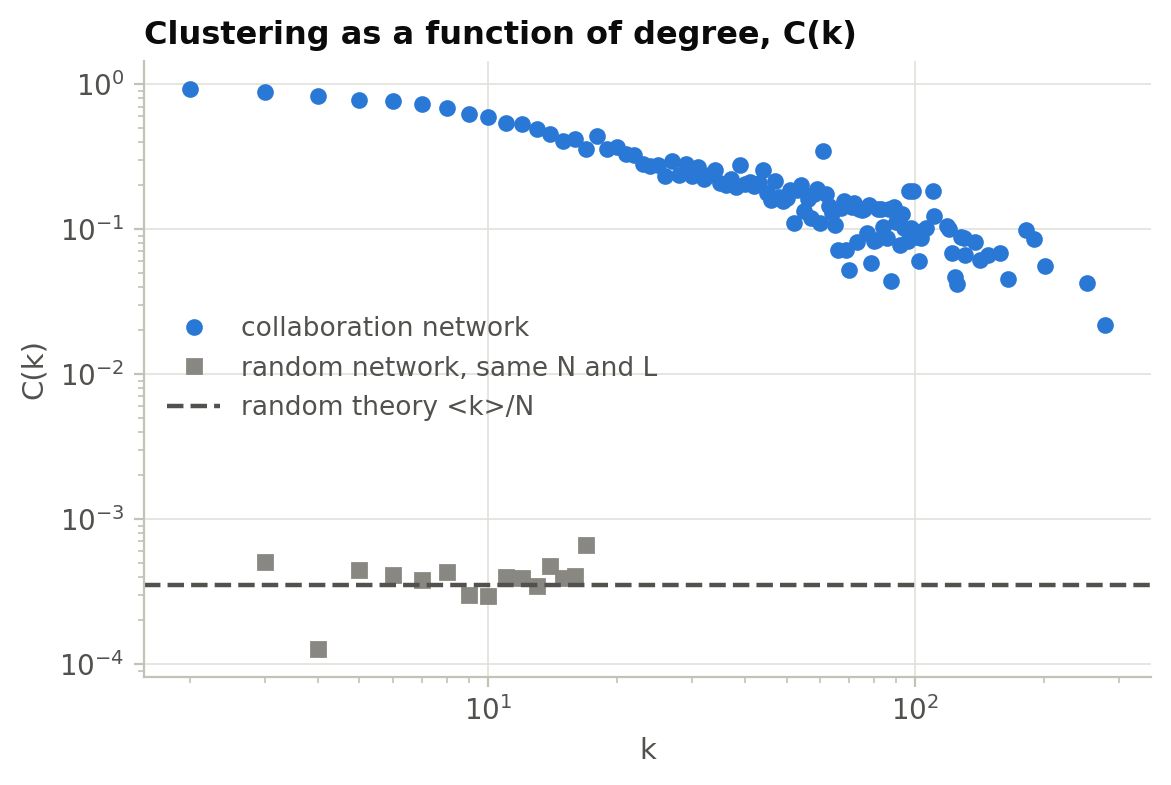

In [23]:
avg_k = 10
for n in [500, 2_000, 8_000, 32_000]:
    g = nx.fast_gnp_random_graph(n, avg_k / (n - 1), seed=SEED)
    print(f"N = {n:6,d}:  <C> simulated = {nx.average_clustering(g):.5f}   theory <k>/N = {avg_k/n:.5f}")

def C_of_k(G):
    # Average local clustering C(k) of the nodes with degree k.
    df = pd.DataFrame({"k": degrees(G), "C": list(nx.clustering(G).values())})
    df = df[df.k > 1].groupby("k").C.mean()
    return df[df > 0]

N, L = G.number_of_nodes(), G.number_of_edges()
G_er = nx.gnm_random_graph(N, L, seed=SEED)              # random counterpart: same N and L
Ck_real, Ck_er = C_of_k(G), C_of_k(G_er)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.loglog(Ck_real.index, Ck_real.values, "o", color=BLUE, ms=5, label="collaboration network")
ax.loglog(Ck_er.index, Ck_er.values, "s", color=MUTED, ms=5, label="random network, same N and L")
ax.axhline(2 * L / N / N, **THEORY, label="random theory <k>/N")
ax.set(title="Clustering as a function of degree, C(k)", xlabel="k", ylabel="C(k)"); ax.legend(); plt.show()

> **Look for:** the real $C(k)$ is **orders of magnitude** above the random prediction and **decreases with $k$**: hubs connect otherwise unconnected groups (compare the karate-club hubs in I.7). The random network is flat and tiny.

### II.8 Summary: real networks are not random (Section 3.10)

In [24]:
summary = pd.DataFrame({"collaboration (real)": describe(G), "random G(N, L)": describe(G_er)}).T
summary

,N,L,<k>,<k^2>,k_max,giant comp. N_G/N,<d> (giant comp.),<C>,assortativity r
collaboration (real),23133.0,93439.0,8.078,178.195,279.0,0.923,5.333,6.334e-01,0.134
"random G(N, L)",23133.0,93439.0,8.078,73.380,21.0,1.000,5.048,3.646e-04,-0.002


> **Discuss:** Which properties does the random network get **right** (giant component, roughly $\langle d\rangle$), and which does it get badly **wrong** ($k_{\max}$, $\langle k^2\rangle$, $\langle C\rangle$)? Chapter 4 addresses the first failure: the degree distribution.

---
## Part III: The scale-free property (Ch 4) *(about 45 min)*

A network is **scale-free** if its degree distribution follows a power law, $p_k \sim k^{-\gamma}$.

| Result | Formula | Book |
|---|---|---|
| Cumulative distribution | $P_k \sim k^{-(\gamma-1)}$ | 4.B |
| Largest hub (natural cutoff) | $k_{\max}\approx k_{\min} N^{1/(\gamma-1)}$; exponential/Poisson: $k_{\max}\sim\ln N$ | 4.3 |
| Moments | $\langle k^n\rangle$ diverges as $N\to\infty$ when $n>\gamma-1$; for $2<\gamma<3$, $\langle k\rangle$ is finite but $\langle k^2\rangle\to\infty$ | 4.4 |
| Distances | $\langle d\rangle\sim$ const ($\gamma=2$), $\ln\ln N$ ($2<\gamma<3$), $\frac{\ln N}{\ln\ln N}$ ($\gamma=3$), $\ln N$ ($\gamma>3$) | 4.6 |
| MLE exponent | $\hat\gamma = 1 + n\left[\sum_{i}\ln\frac{k_i}{k_{\min}-1/2}\right]^{-1}$ | 4.C |

Throughout this part, our largest undirected example is the **Internet** at the router level ($N\approx 1.9\times10^5$).

### III.1 How (not) to plot a degree distribution (Advanced Topic 4.B)

Internet: N = 192,244, <k> = 6.34, k_max = 1,071  [book data]


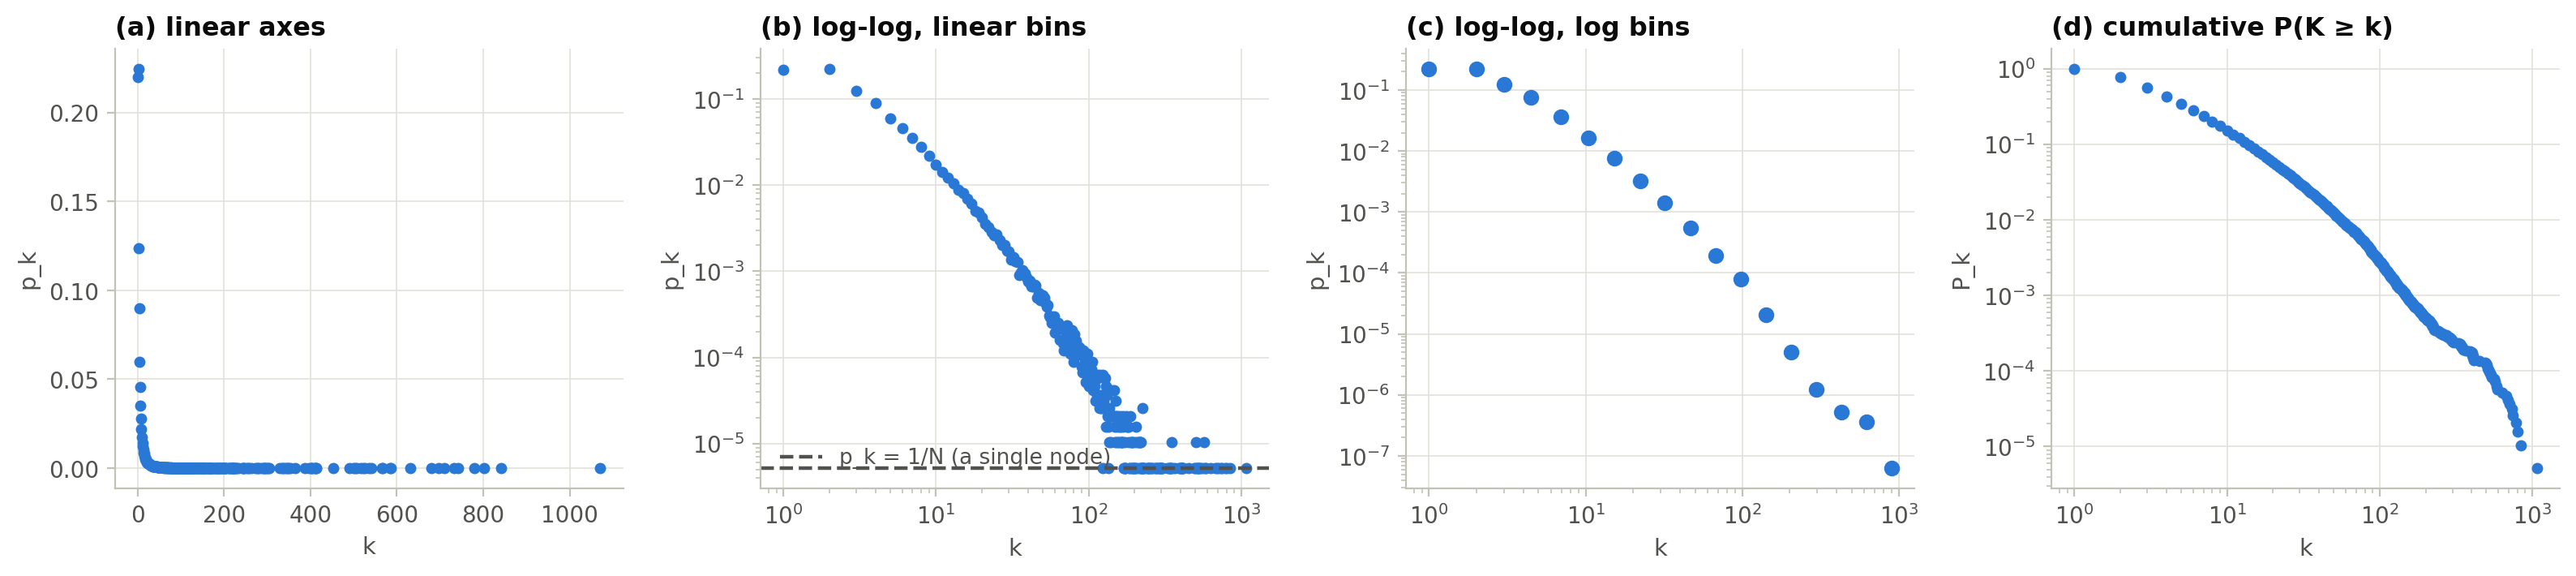

In [25]:
k_int = load_degrees("internet")
print(f"Internet: N = {k_int.size:,}, <k> = {k_int.mean():.2f}, k_max = {k_int.max():,}  [{load_edges('internet')[2]}]")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.7))
ks, pk = pk_linear(k_int)
axes[0].plot(ks, pk, "o", color=BLUE, ms=4)
axes[0].set(title="(a) linear axes", xlabel="k", ylabel="p_k")
axes[1].loglog(ks, pk, "o", color=BLUE, ms=4)
axes[1].axhline(1 / k_int.size, **THEORY, label="p_k = 1/N (a single node)"); axes[1].legend(loc="lower left")
axes[1].set(title="(b) log-log, linear bins", xlabel="k", ylabel="p_k")
kb, pb = pk_logbinned(k_int)
axes[2].loglog(kb, pb, "o", color=BLUE, ms=6)
axes[2].set(title="(c) log-log, log bins", xlabel="k", ylabel="p_k")
kq, Pq = ccdf(k_int)
axes[3].loglog(kq, Pq, "o", color=BLUE, ms=4)
axes[3].set(title="(d) cumulative P(K ≥ k)", xlabel="k", ylabel="P_k")
plt.tight_layout(); plt.show()

> **Look for:**
> * **(a)** All the information about the tail is invisible.
> * **(b)** The tail flattens into a plateau at $p_k = 1/N$, because each degree there is held by 0 or 1 node. This is *noise, not physics*.
> * **(c)** Log-binning averages the noise away and reveals a straight line.
> * **(d)** The cumulative distribution needs no binning at all; its slope is $-(\gamma-1)$.

### III.2 Power law vs. Poisson: where the hubs live (Section 4.2)

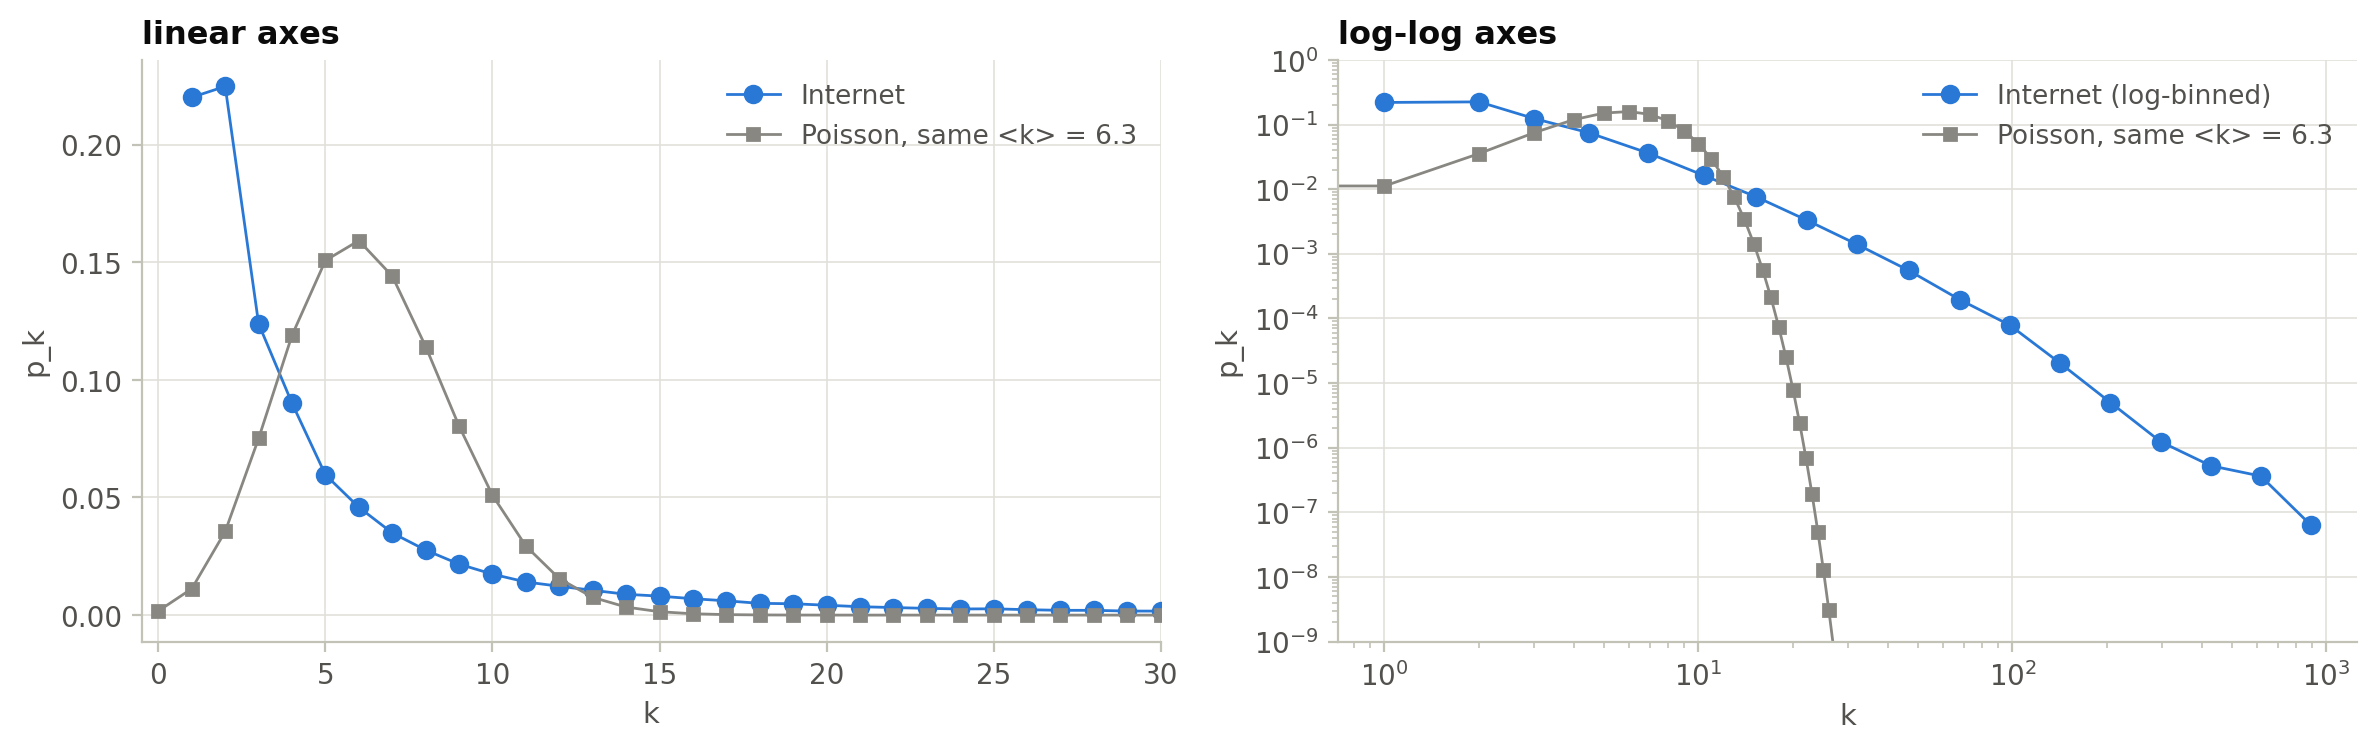

In [26]:
avg = k_int.mean(); kk = np.arange(0, 60)
ks, pk = pk_linear(k_int)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
axes[0].plot(ks, pk, "o-", color=BLUE, ms=6, lw=1, label="Internet")
axes[0].set(xlim=(-0.5, 30), title="linear axes")
axes[1].plot(kb, pb, "o-", color=BLUE, ms=6, lw=1, label="Internet (log-binned)")
axes[1].set(xscale="log", yscale="log", ylim=(1e-9, 1), title="log-log axes")
for ax in axes:
    ax.plot(kk, stats.poisson.pmf(kk, avg), "s-", color=MUTED, ms=4, lw=1, label=f"Poisson, same <k> = {avg:.1f}")
    ax.set(xlabel="k", ylabel="p_k"); ax.legend()
plt.tight_layout(); plt.show()

> **Look for:** compared with the Poisson curve, the power law has **more** low-degree nodes, **fewer** nodes with $k\approx\langle k\rangle$, and **vastly more** high-degree nodes (book Fig. 4.4). In the scale-free network a "typical" node with $k\approx\langle k\rangle$ is not typical at all.

### III.3 Estimating the degree exponent (Advanced Topic 4.C)
**First, a controlled experiment.** We draw $n=10^4$ degrees from a power law with a *known* $\gamma = 2.5$ and see which estimator recovers it.

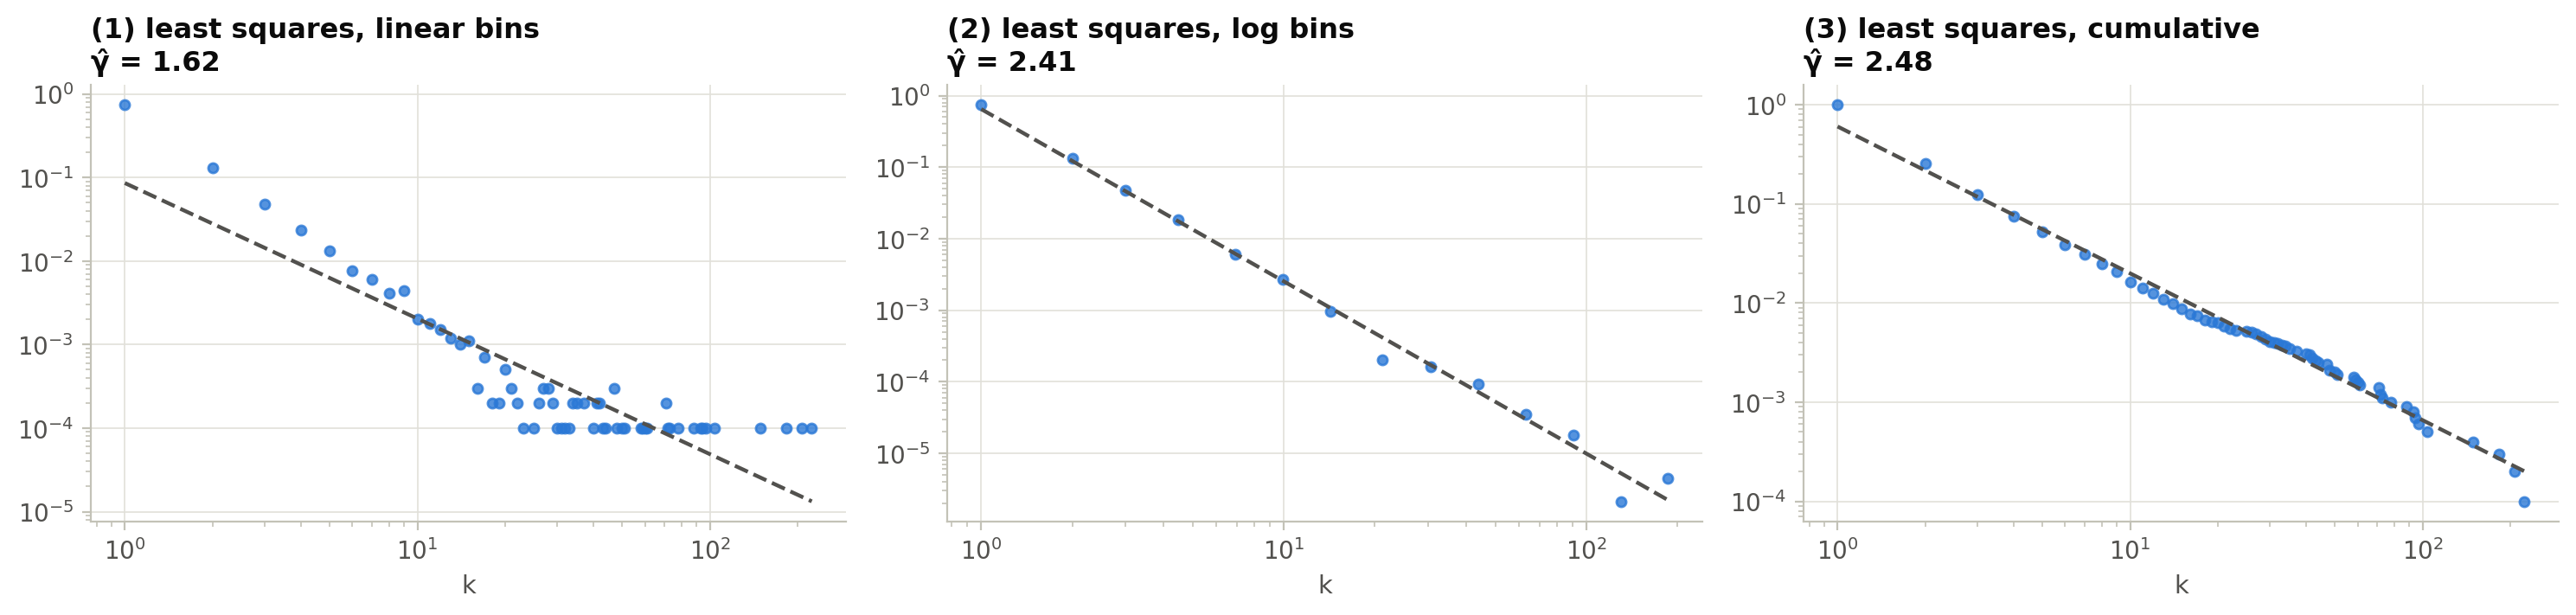

,estimated γ (true value 2.5)
"(1) least squares, linear bins",1.623
"(2) least squares, log bins",2.407
"(3) least squares, cumulative",2.481
"(4) MLE closed form, tail k ≥ 6",2.431
"(5) exact MLE (powerlaw), k_min = 1",2.496


In [27]:
gamma_true, n = 2.5, 10_000
np.random.seed(SEED)
x = powerlaw.Power_Law(xmin=1, parameters=[gamma_true], discrete=True).generate_random(n).astype(int)

def ls_slope(xv, yv):
    return np.polyfit(np.log10(xv), np.log10(yv), 1)

ks, pk = pk_linear(x); kb, pb = pk_logbinned(x); kq, Pq = ccdf(x)
fits = {"(1) least squares, linear bins": (ks, pk, ls_slope(ks, pk), 0),
        "(2) least squares, log bins":    (kb, pb, ls_slope(kb, pb), 0),
        "(3) least squares, cumulative":   (kq, Pq, ls_slope(kq, Pq), 1)}

fig, axes = plt.subplots(1, 3, figsize=(15, 3.7), sharey=False)
estimates = {}
for ax, (label, (xv, yv, (slope, icpt), shift)) in zip(axes, fits.items()):
    g_hat = -slope + shift
    estimates[label] = g_hat
    ax.loglog(xv, yv, "o", color=BLUE, ms=4, alpha=0.8)
    xx = np.array([xv.min(), xv.max()])
    ax.loglog(xx, 10**icpt * xx**slope, **THEORY)
    ax.set(title=f"{label}\nγ̂ = {g_hat:.2f}", xlabel="k")

# (4) the closed-form MLE of Advanced Topic 4.C. It is an approximation that is accurate only for
#     k_min >~ 6, so we apply it to the tail k >= 6 (a pure power law's tail has the same exponent).
tail6 = x[x >= 6]
estimates["(4) MLE closed form, tail k ≥ 6"] = 1 + tail6.size / np.sum(np.log(tail6 / (6 - 0.5)))
# (5) the exact discrete MLE (numerical), using all the data
estimates["(5) exact MLE (powerlaw), k_min = 1"] = fit_powerlaw(x, xmin=1).power_law.alpha
plt.tight_layout(); plt.show()
pd.Series(estimates, name=f"estimated γ (true value {gamma_true})").to_frame()

> **Look for:** a straight-line fit to the *raw* log-log histogram (1) is badly biased by the noisy tail. Log-binning (2) and the cumulative plot (3) do better, but least squares on a log-log plot has no statistical justification: it gives no reliable error bars and depends on the binning and fitting range. Maximum likelihood (4, 5) recovers the true value within its statistical error (estimator 4 uses only the tail $k\ge 6$, so it is noisier). **Never fit a straight line to a linearly binned log-log histogram.**
>
> *Note on (4):* applied to all the data with $k_{\min}=1$, the closed-form formula gives about 2.0 instead of 2.5. It assumes the discrete distribution behaves like a continuous one, which only holds for $k_{\min}\gtrsim 6$ (Clauset et al. 2009). For small $k_{\min}$, use the exact numerical MLE, as the `powerlaw` package does.

**Now the real data.** For real networks we do not know where the power law starts. The Clauset–Shalizi–Newman recipe chooses the $k_{\min}$ for which the fitted power law is closest to the data (minimum Kolmogorov–Smirnov distance $D$), and fits $\gamma$ by MLE on $k\ge k_{\min}$.

> **A software gotcha worth showing students.** Version 2 of the `powerlaw` package restricts the exponent to $\gamma\le 3$ by default. With that default, the Internet comes out at $\gamma\approx 2.9$ with $k_{\min}=36$. With the restriction lifted (our `fit_powerlaw` helper does this), we recover the book's value of about 3.4. Always check the defaults of a fitting routine.

Internet: k_min = 70,  γ = 3.40 ± 0.07,  the tail k >= k_min holds 1,286 nodes (0.7%)


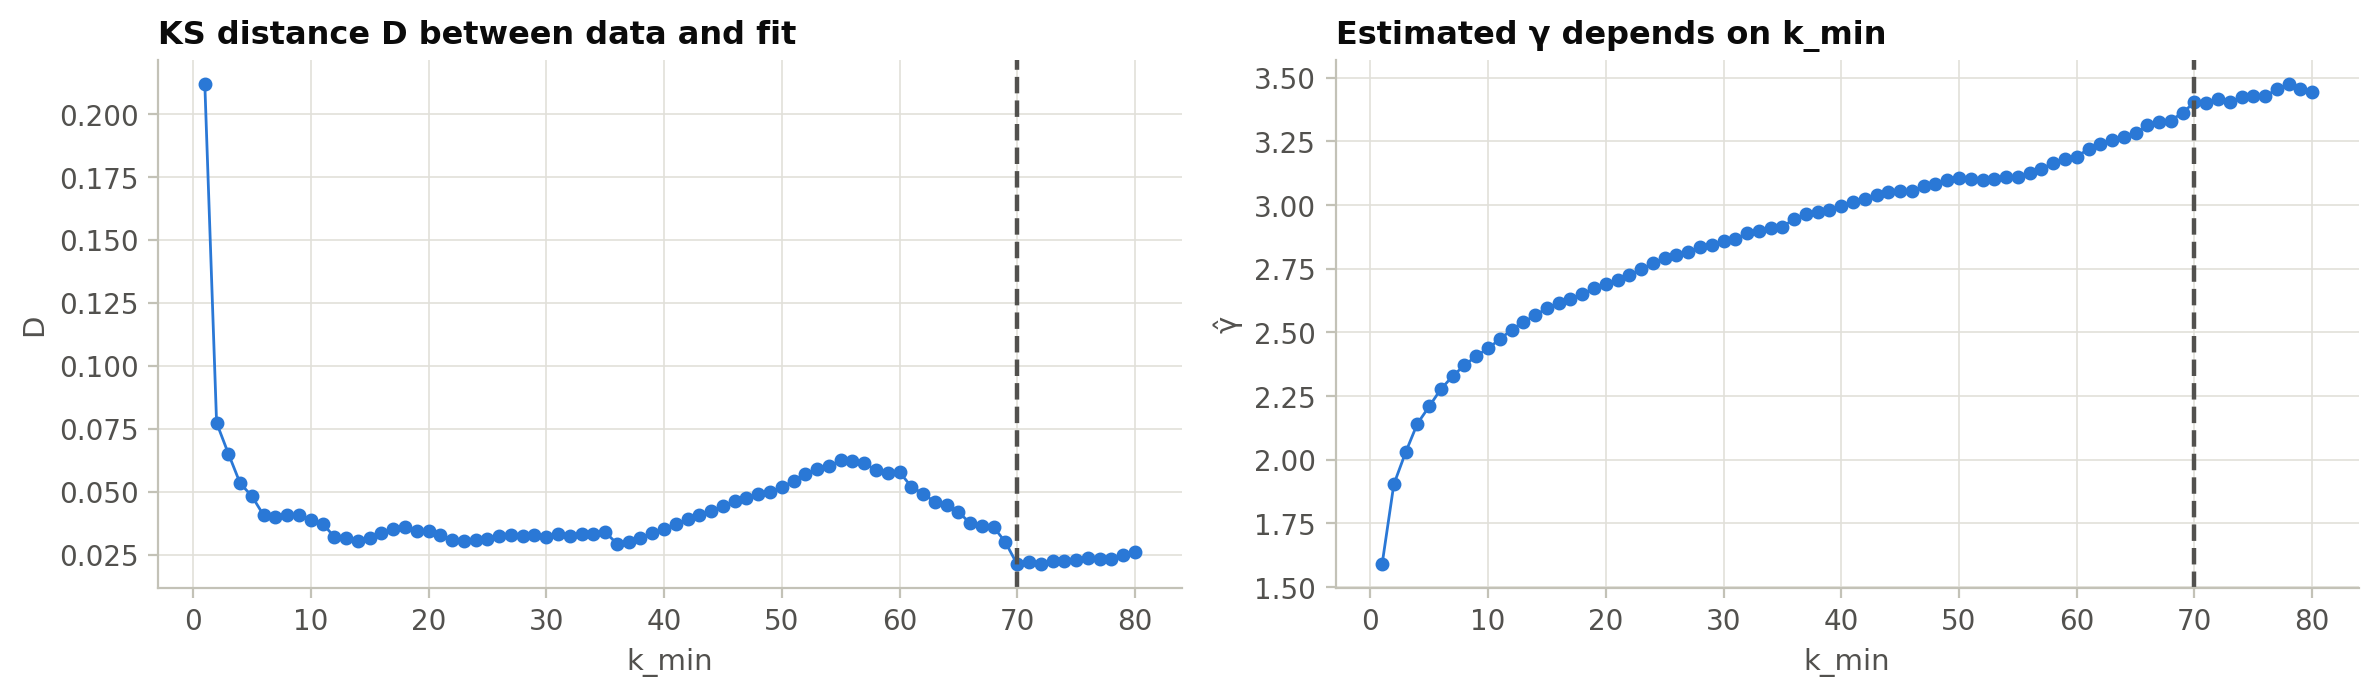

In [28]:
fit_int = fit_powerlaw(k_int)
n_tail = (k_int >= fit_int.xmin).sum()
print(f"Internet: k_min = {fit_int.xmin:.0f},  γ = {fit_int.power_law.alpha:.2f} ± {fit_int.power_law.sigma:.2f},  "
      f"the tail k >= k_min holds {n_tail:,} nodes ({n_tail/k_int.size:.1%})")

# How sensitive is γ to the choice of k_min?  Scan k_min ourselves.
cands = np.unique(k_int)[:80]
scan = pd.DataFrame([(km, f.power_law.D, f.power_law.alpha) for km in cands for f in [fit_powerlaw(k_int, xmin=km)]],
                    columns=["k_min", "D", "gamma"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(scan.k_min, scan.D, "o-", color=BLUE, ms=4, lw=1)
axes[0].set(title="KS distance D between data and fit", xlabel="k_min", ylabel="D")
axes[1].plot(scan.k_min, scan.gamma, "o-", color=BLUE, ms=4, lw=1)
axes[1].set(title="Estimated γ depends on k_min", xlabel="k_min", ylabel="γ̂")
for ax in axes:
    ax.axvline(fit_int.xmin, **THEORY)
plt.tight_layout(); plt.show()

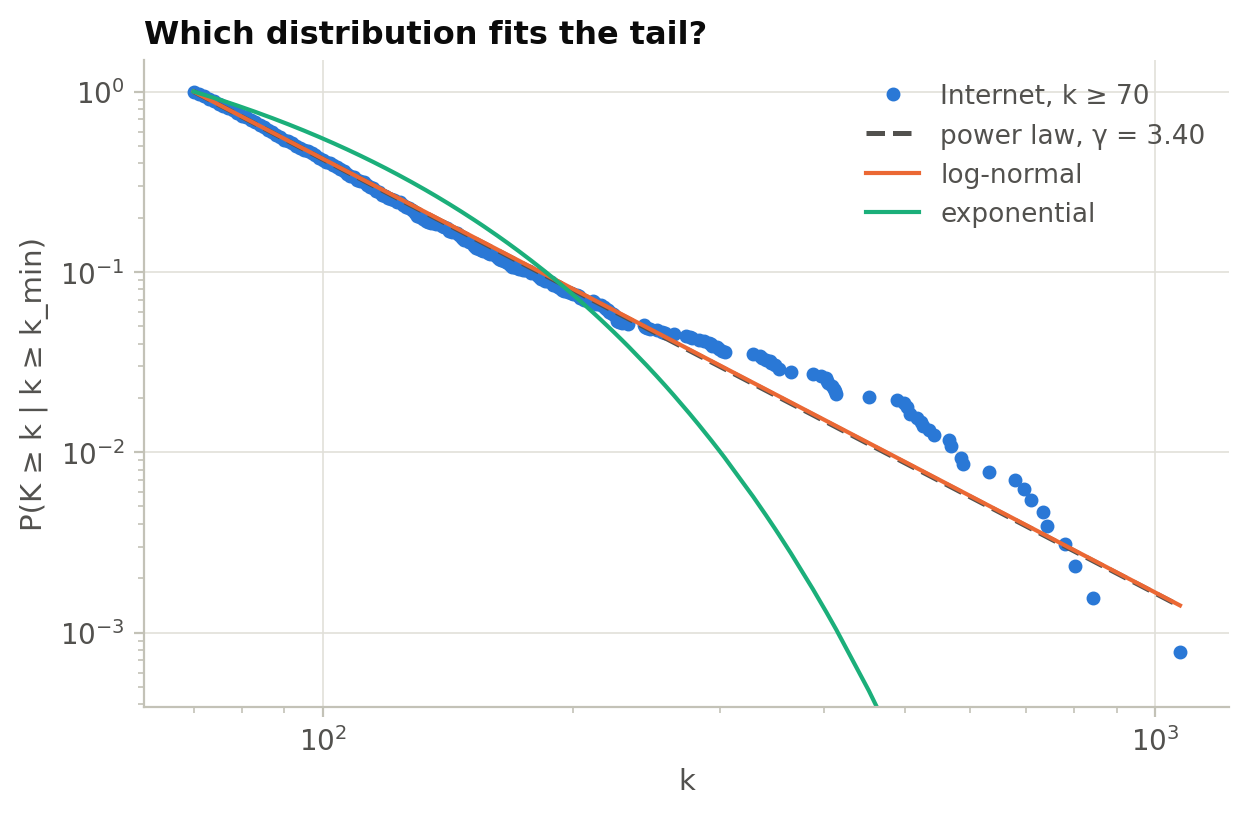

,R (normalised log-likelihood ratio),p-value
exponential,6.424e+00,1.324e-10
lognormal,7.522e-01,4.519e-01
truncated_power_law,3.058e-04,9.992e-01


In [29]:
fig, ax = plt.subplots(figsize=(7, 4.2))
fit_int.plot_ccdf(ax=ax, color=BLUE, marker="o", ls="", ms=4, label=f"Internet, k ≥ {fit_int.xmin:.0f}")
fit_int.power_law.plot_ccdf(ax=ax, color=INK2, ls="--", lw=1.8, label=f"power law, γ = {fit_int.power_law.alpha:.2f}")
fit_int.lognormal.plot_ccdf(ax=ax, color=ORANGE, ls="-", lw=1.5, label="log-normal")
fit_int.exponential.plot_ccdf(ax=ax, color=AQUA, ls="-", lw=1.5, label="exponential")
ax.set(ylim=(1 / n_tail / 2, 1.5), title="Which distribution fits the tail?", xlabel="k", ylabel="P(K ≥ k | k ≥ k_min)")
ax.legend(); plt.show()

# Likelihood-ratio tests: R > 0 favours the power law; p < 0.1 means the sign of R is significant.
lr = {alt: fit_int.distribution_compare("power_law", alt, normalized_ratio=True)
      for alt in ["exponential", "lognormal", "truncated_power_law"]}
pd.DataFrame(lr, index=["R (normalised log-likelihood ratio)", "p-value"]).T

> **Look for:** the power law beats the exponential decisively, so the tail is *heavy*. Against the log-normal or a power law with an exponential cutoff, the comparison is often inconclusive or tilts toward the alternative.
>
> **Discuss: is the Internet "scale-free"?** This question started a lively debate:
> * Clauset, Shalizi & Newman, *SIAM Review* 51, 661 (2009): rigorous methodology, under which many claimed power laws are not statistically supported.
> * Broido & Clauset, *Nature Communications* 10, 1017 (2019), "Scale-free networks are rare".
> * Holme, *Nat. Commun.* 10, 1016 (2019), and Voitalov et al., *Phys. Rev. Research* 1, 033034 (2019): replies arguing that the right question is whether the tail is heavy, i.e. whether $\langle k^2\rangle$ is large.
>
> For most of the consequences in Ch 4 and later chapters (hubs, ultra-small distances, robustness, epidemics), **what matters is the heavy tail and the large $\langle k^2\rangle$**, not whether the tail is exactly a power law.

### III.4 Hubs (Section 4.3)
How does the largest degree grow with network size? We sample $N$ degrees from a power law ($\gamma=2.5$, $k_{\min}=1$) and from an exponential distribution with the same mean.

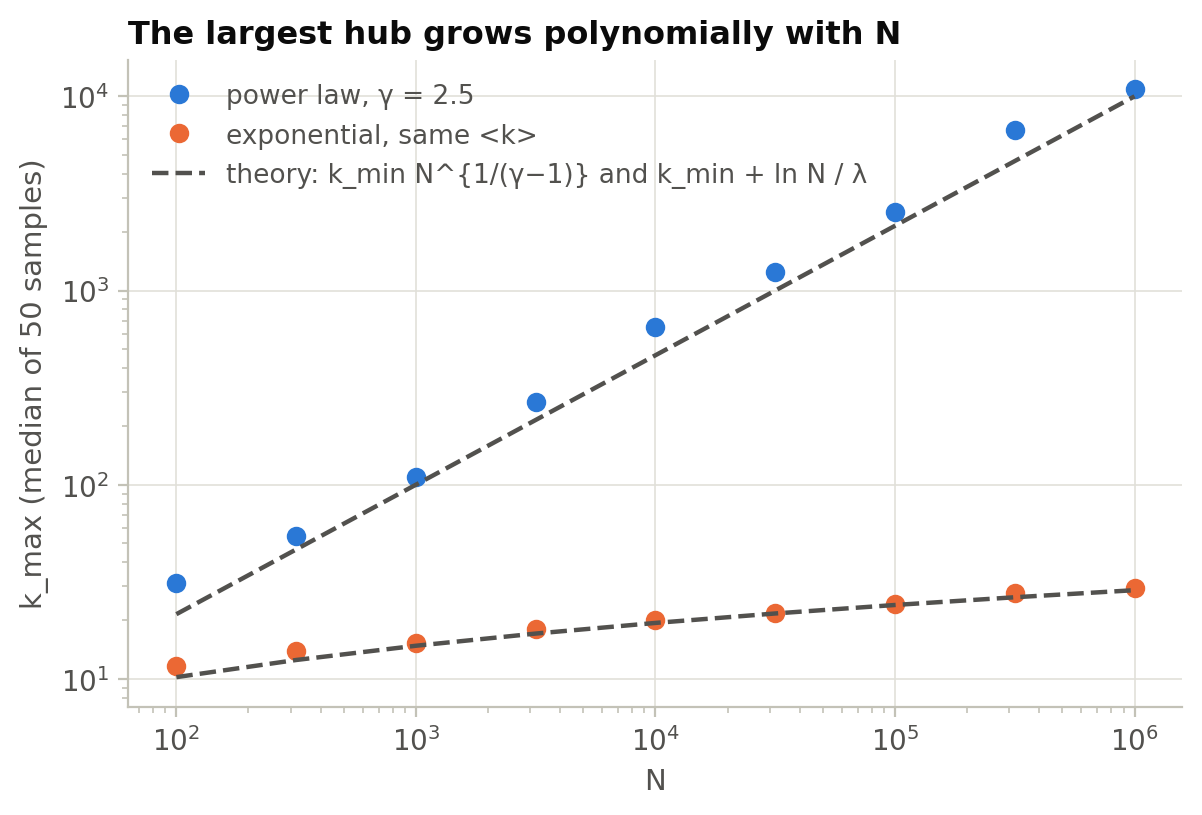

At N = 10^6: power-law hub ≈ 10,889, exponential 'hub' ≈ 29


In [30]:
gamma, kmin, reps = 2.5, 1, 50
mean_k = kmin * (gamma - 1) / (gamma - 2)          # = 3 for these parameters
lam = 1 / (mean_k - kmin)                          # exponential p(k) = λ e^{-λ(k - k_min)} with the same mean
Ns = np.logspace(2, 6, 9).astype(int)
r = np.random.default_rng(SEED)
# k_max of a heavy-tailed sample fluctuates wildly between samples, so we report the median over 50 samples
kmax_pl  = [np.median([(kmin * (1 - r.random(n)) ** (-1 / (gamma - 1))).max() for _ in range(reps)]) for n in Ns]
kmax_exp = [np.median([(kmin + r.exponential(1 / lam, n)).max() for _ in range(reps)]) for n in Ns]

fig, ax = plt.subplots(figsize=(6.8, 4.2))
ax.loglog(Ns, kmax_pl, "o", color=BLUE, label=f"power law, γ = {gamma}")
ax.loglog(Ns, kmax_exp, "o", color=ORANGE, label="exponential, same <k>")
ax.loglog(Ns, kmin * Ns ** (1 / (gamma - 1)), **THEORY, label="theory: k_min N^{1/(γ−1)} and k_min + ln N / λ")
ax.loglog(Ns, kmin + np.log(Ns) / lam, **THEORY)
ax.set(title="The largest hub grows polynomially with N", xlabel="N", ylabel="k_max (median of 50 samples)"); ax.legend()
plt.show()
print(f"At N = 10^6: power-law hub ≈ {kmax_pl[-1]:,.0f}, exponential 'hub' ≈ {kmax_exp[-1]:.0f}")

In [31]:
# The same check on real networks: observed k_max vs. Poisson and vs. the natural cutoff of the fitted tail
rows = []
for name in ["collaboration", "internet", "www"]:
    kr = load_degrees(name); f = fit_powerlaw(kr); ntail = (kr >= f.xmin).sum()
    rows.append({"network": DATASETS[name][0], "N": kr.size, "observed k_max": kr.max(),
                 "Poisson k_max": stats.poisson.isf(1 / kr.size, kr.mean()),
                 "power-law k_max = k_min·n_tail^(1/(γ-1))": f.xmin * ntail ** (1 / (f.power_law.alpha - 1)),
                 "k_min": f.xmin, "γ̂": f.power_law.alpha})
pd.DataFrame(rows).set_index("network").round({"Poisson k_max": 0, "power-law k_max = k_min·n_tail^(1/(γ-1))": 0, "γ̂": 2})

,N,observed k_max,Poisson k_max,power-law k_max = k_min·n_tail^(1/(γ-1)),k_min,γ̂
network,,,,,,
Science collaboration,23133,279,21.0,479.0,27.0,3.43
Internet (routers),192244,1071,20.0,1378.0,70.0,3.40
WWW (nd.edu pages),325729,10721,21.0,102315.0,6.0,2.16


> **Look for:** the observed hubs lie **between** the two predictions. The Poisson prediction is one to three orders of magnitude too small. Extrapolating the fitted power law to its natural cutoff overshoots, by a factor of roughly 1.3 to 10: real tails usually bend down at the very highest degrees (finite size, the cost of maintaining links, limited time). This bending is also why the log-normal and the truncated power law compete with the pure power law in III.3.

### III.5 What "scale-free" means: diverging moments (Section 4.4)

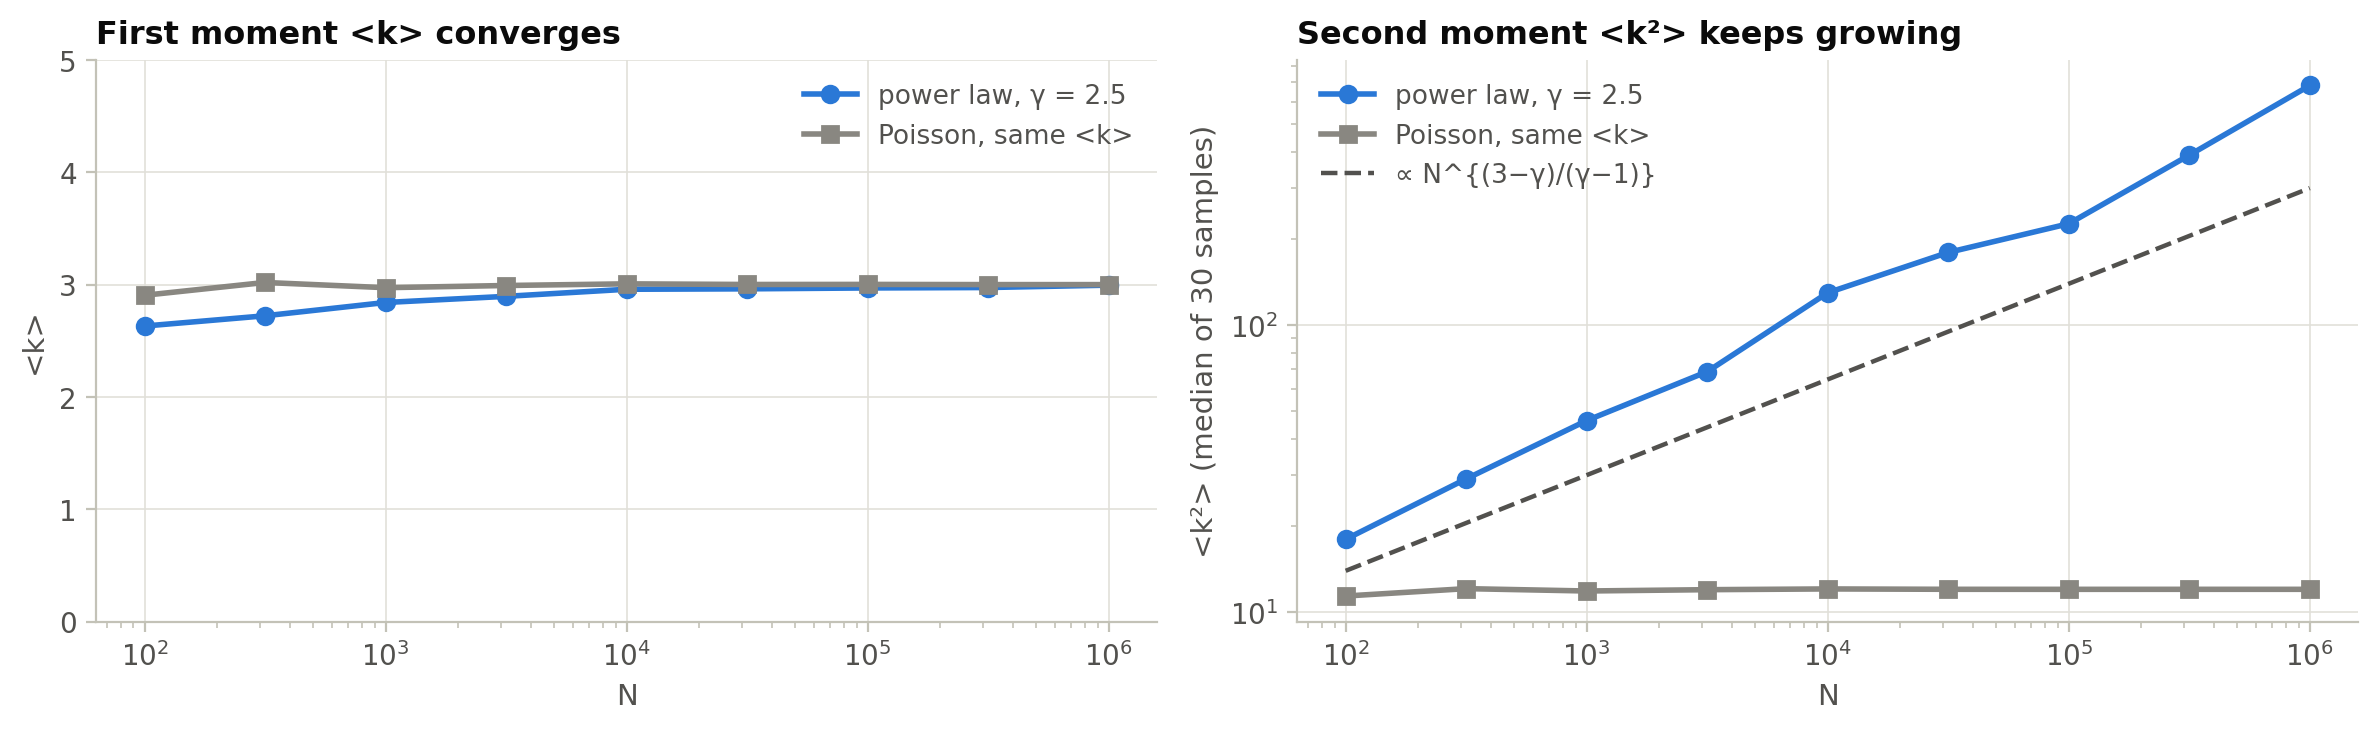

In [32]:
reps = 30
m1_pl, m2_pl, m1_po, m2_po = [], [], [], []
for n in Ns:
    s_pl = [kmin * (1 - r.random(n)) ** (-1 / (gamma - 1)) for _ in range(reps)]
    s_po = [r.poisson(mean_k, n) for _ in range(reps)]
    m1_pl.append(np.median([s.mean() for s in s_pl])); m2_pl.append(np.median([(s**2).mean() for s in s_pl]))
    m1_po.append(np.median([s.mean() for s in s_po])); m2_po.append(np.median([(s**2).mean() for s in s_po]))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].semilogx(Ns, m1_pl, "o-", color=BLUE, label=f"power law, γ = {gamma}")
axes[0].semilogx(Ns, m1_po, "s-", color=MUTED, label="Poisson, same <k>")
axes[0].set(title="First moment <k> converges", xlabel="N", ylabel="<k>", ylim=(0, 5)); axes[0].legend()
axes[1].loglog(Ns, m2_pl, "o-", color=BLUE, label=f"power law, γ = {gamma}")
axes[1].loglog(Ns, m2_po, "s-", color=MUTED, label="Poisson, same <k>")
axes[1].loglog(Ns, 3 * Ns ** ((3 - gamma) / (gamma - 1)), **THEORY, label="∝ N^{(3−γ)/(γ−1)}")
axes[1].set(title="Second moment <k²> keeps growing", xlabel="N", ylabel="<k²> (median of 30 samples)"); axes[1].legend()
plt.tight_layout(); plt.show()

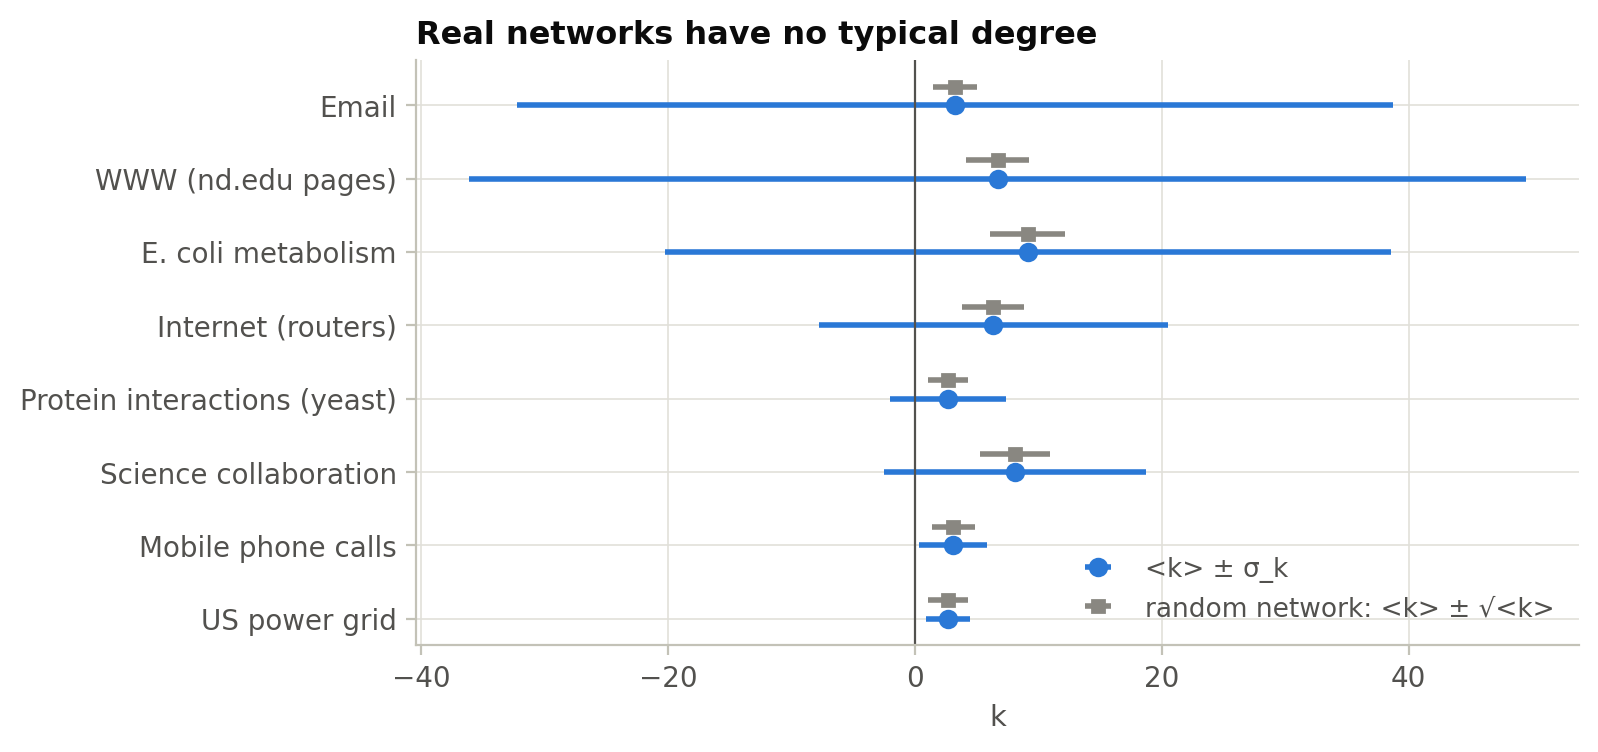

,<k>,σ_k,σ_k / <k>,<k²>/<k>,Poisson σ_k = √<k>
network,,,,,
US power grid,2.669,1.791,0.671,3.871,1.634
Mobile phone calls,3.107,2.765,0.890,5.567,1.763
Science collaboration,8.078,10.627,1.315,22.058,2.842
Protein interactions (yeast),2.681,4.710,1.757,10.957,1.637
Internet (routers),6.336,14.140,2.232,37.890,2.517
E. coli metabolism,9.126,29.413,3.223,103.923,3.021
WWW (nd.edu pages),6.693,42.824,6.398,280.680,2.587
Email,3.233,35.477,10.975,392.576,1.798


In [33]:
# In real networks: is <k> a "typical" degree?  k = <k> ± σ_k (book Fig. 4.8)
rows = []
for name, (desc, _) in DATASETS.items():
    kr = load_degrees(name)
    rows.append({"network": desc, "<k>": kr.mean(), "σ_k": kr.std(), "σ_k / <k>": kr.std() / kr.mean(),
                 "<k²>/<k>": (kr**2).mean() / kr.mean(), "Poisson σ_k = √<k>": np.sqrt(kr.mean())})
het = pd.DataFrame(rows).set_index("network").sort_values("σ_k / <k>")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
y = np.arange(len(het))
ax.errorbar(het["<k>"], y, xerr=het["σ_k"], fmt="o", color=BLUE, ecolor=BLUE, elinewidth=2, capsize=0, label="<k> ± σ_k")
ax.errorbar(het["<k>"], y + 0.25, xerr=het["Poisson σ_k = √<k>"], fmt="s", color=MUTED, ecolor=MUTED, elinewidth=2,
            capsize=0, ms=4, label="random network: <k> ± √<k>")
ax.set_yticks(y); ax.set_yticklabels(het.index); ax.axvline(0, color=INK2, lw=0.8)
ax.set(title="Real networks have no typical degree", xlabel="k"); ax.legend(loc="lower right"); plt.show()
het

> **Look for:** in a random network $\sigma_k=\sqrt{\langle k\rangle}$, so almost every node has a degree close to $\langle k\rangle$ and the average sets a *scale*. In most real networks $\sigma_k$ is larger than $\langle k\rangle$, up to 11 times larger for email. A randomly chosen node could have degree 1 or degree 1,000, and there is no characteristic scale, hence the name **scale-free**. The power grid and the mobile-phone network are the exceptions, with $\sigma_k < \langle k\rangle$.

### III.6 Universality (Section 4.5)
We apply the same fitting procedure to all eight networks. Compare the results with Table 4.1 in the book.

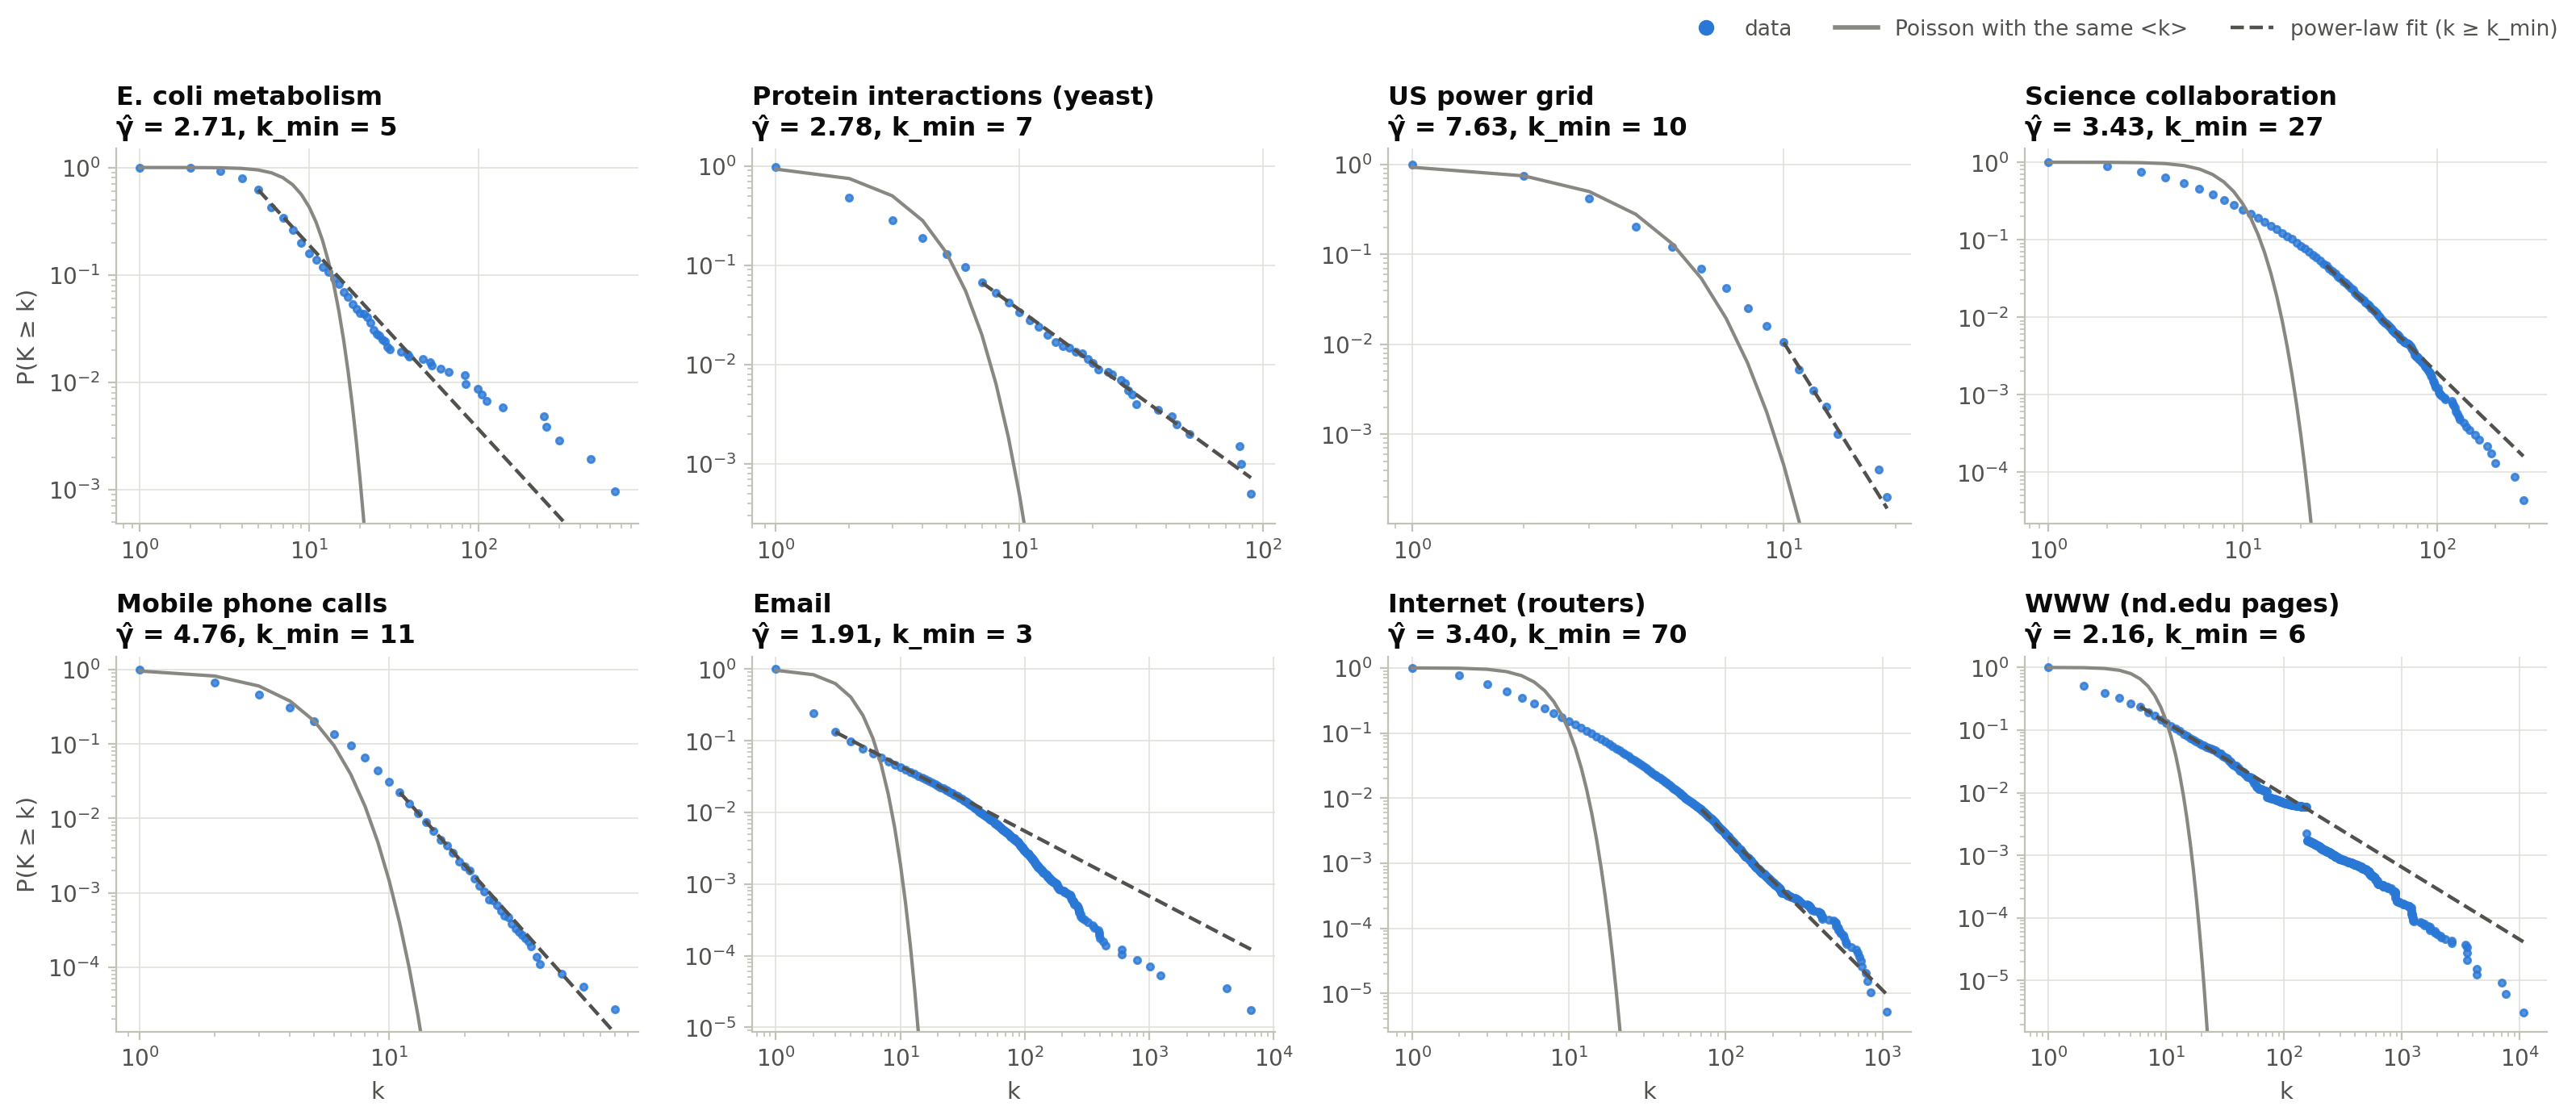

,N,<k>,<k²>,k_max,k_min,γ̂,±,tail share,R vs exp,p (exp),R vs lognormal,p (lognormal)
network,,,,,,,,,,,,
E. coli metabolism,1039,9.126,948.406,638,5.0,2.714,0.067,0.621,3.961,7.464e-05,-1.004,3.152e-01
Protein interactions (yeast),2018,2.681,29.374,89,7.0,2.783,0.153,0.067,2.558,1.052e-02,-0.211,8.330e-01
US power grid,4941,2.669,10.333,19,10.0,7.629,0.919,0.011,0.527,5.980e-01,-0.055,9.563e-01
Science collaboration,23133,8.078,178.195,279,27.0,3.426,0.074,0.046,2.416,1.569e-02,-1.971,4.877e-02
Mobile phone calls,36595,3.107,17.299,80,11.0,4.756,0.131,0.022,2.532,1.135e-02,-0.117,9.065e-01
Email,57194,3.233,1269.033,6553,3.0,1.908,0.010,0.132,7.569,3.753e-14,-5.488,4.069e-08
Internet (routers),192244,6.336,240.089,1071,70.0,3.403,0.067,0.007,6.424,1.324e-10,0.752,4.519e-01
WWW (nd.edu pages),325729,6.693,1878.686,10721,6.0,2.155,0.004,0.238,25.387,3.515e-142,-10.497,8.872e-26


In [34]:
rows, fitted = [], {}
for name, (desc, _) in DATASETS.items():
    kr = load_degrees(name); f = fit_powerlaw(kr); fitted[name] = (kr, f)
    R_exp, p_exp = f.distribution_compare("power_law", "exponential", normalized_ratio=True)
    R_ln, p_ln = f.distribution_compare("power_law", "lognormal", normalized_ratio=True)
    rows.append({"network": desc, "N": kr.size, "<k>": kr.mean(), "<k²>": (kr**2).mean(), "k_max": kr.max(),
                 "k_min": f.xmin, "γ̂": f.power_law.alpha, "±": f.power_law.sigma, "tail share": (kr >= f.xmin).mean(),
                 "R vs exp": R_exp, "p (exp)": p_exp, "R vs lognormal": R_ln, "p (lognormal)": p_ln})
universality = pd.DataFrame(rows).set_index("network")

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, (name, (kr, f)) in zip(axes.flat, fitted.items()):
    kq, Pq = ccdf(kr)
    ax.loglog(kq, Pq, "o", color=BLUE, ms=3, alpha=0.8)
    kk = np.arange(1, max(int(kr.mean() * 6), 12))
    ax.loglog(kk, stats.poisson.sf(kk - 1, kr.mean()), "-", color=MUTED, lw=1.5)
    tail = np.logspace(np.log10(f.xmin), np.log10(kr.max()), 30)
    ax.loglog(tail, (kr >= f.xmin).mean() * (tail / f.xmin) ** (1 - f.power_law.alpha), **THEORY)
    ax.set(title=f"{DATASETS[name][0]}\nγ̂ = {f.power_law.alpha:.2f}, k_min = {f.xmin:.0f}", ylim=(0.5 / kr.size, 1.5))
    ax.title.set_fontsize(10)
for ax in axes[1]: ax.set_xlabel("k")
for ax in axes[:, 0]: ax.set_ylabel("P(K ≥ k)")
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=BLUE, label="data"),
                    Line2D([], [], color=MUTED, label="Poisson with the same <k>"),
                    Line2D([], [], **THEORY, label="power-law fit (k ≥ k_min)")], loc="upper right", ncol=3)
plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()
universality

> **Look for:**
> * Very different systems (biological, technological, social, information) all have heavy-tailed degree distributions, far from Poisson. This is the book's *universality* claim.
> * The **power grid** is the clear exception. The best "power law" the procedure can find has $\hat\gamma\approx 7.6$ and covers about 1% of the nodes, and it cannot be distinguished from an exponential tail. This fits a system constrained by geography and engineering cost.
> * The **mobile-phone** network has a steep tail ($\hat\gamma\approx 4.8$), deep in the random-like regime $\gamma>3$ (Section 4.7).
> * WWW and email fall at $\hat\gamma\approx 2$, at the edge of the anomalous regime.
> * Our Internet estimate ($\hat\gamma\approx 3.4$) agrees with the book's Table 4.1. Remember that for directed networks the book fits in- and out-degrees separately.
> * Fitted $k_{\min}$ values can be large, so the power law sometimes describes only a small share of the nodes. For the Internet it covers less than 1% (see the `tail share` column). The log-normal is often an equally good or better description of the tail.

### III.7 The ultra-small world (Section 4.6)
We build configuration-model networks with power-law degrees ($k_{\min}=2$) and compare their average distances with a random network as $N$ grows.

computed in 18 s


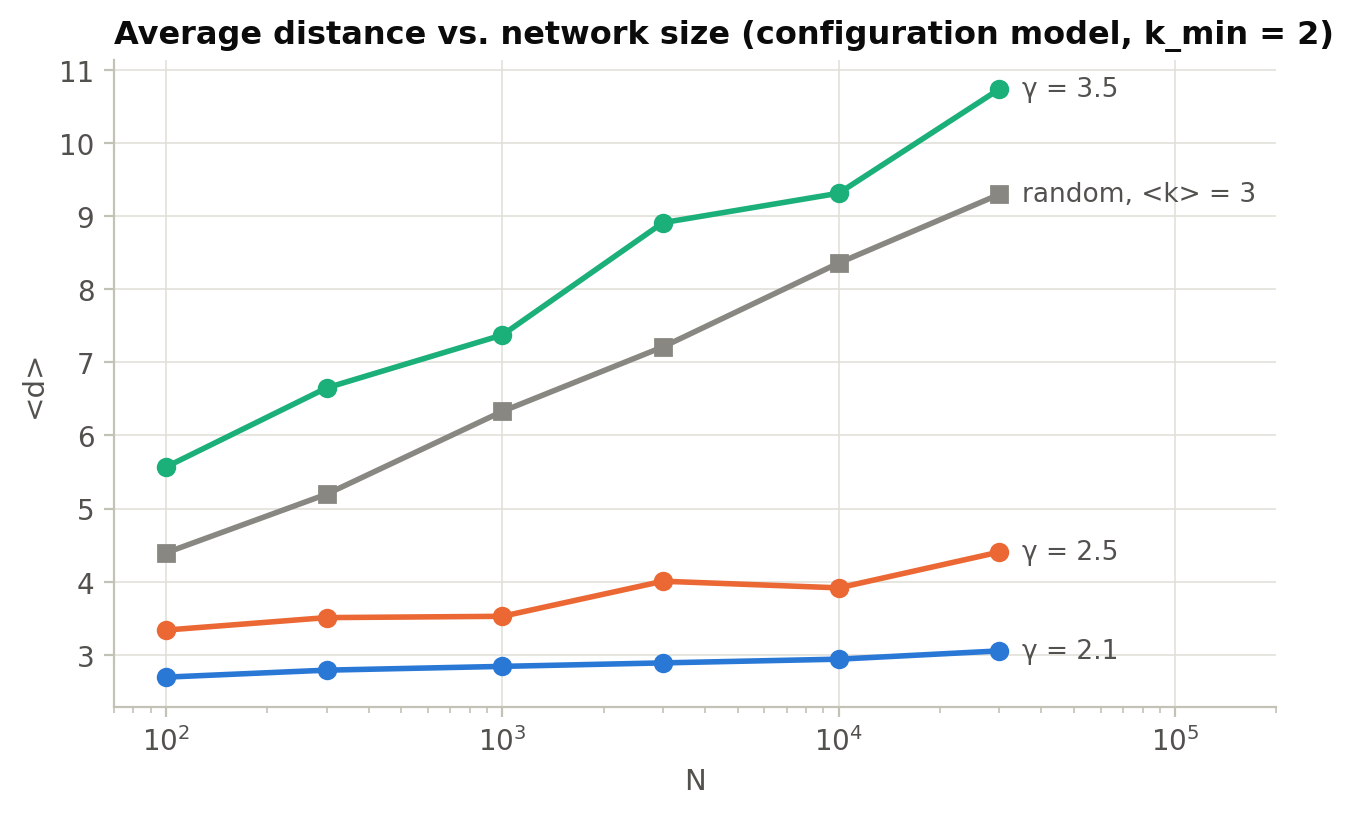

In [35]:
Ns_d = np.array([100, 300, 1_000, 3_000, 10_000, 30_000])
models = {"γ = 2.1": 2.1, "γ = 2.5": 2.5, "γ = 3.5": 3.5}
t0 = time.time()
res = {}
reps = 3
for label, g in models.items():
    res[label] = [np.mean([distance_sample(configuration_graph(powerlaw_degree_sequence(n, g, kmin=2, seed=s), seed=s), 100, seed=s).mean()
                           for s in range(reps)]) for n in Ns_d]
res["random, <k> = 3"] = [np.mean([distance_sample(nx.fast_gnp_random_graph(n, 3 / (n - 1), seed=s), 100, seed=s).mean()
                                   for s in range(reps)]) for n in Ns_d]
print(f"computed in {time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for (label, vals), c in zip(res.items(), [BLUE, ORANGE, AQUA, MUTED]):
    ax.semilogx(Ns_d, vals, "o-" if c != MUTED else "s-", color=c)
    ax.annotate(label, (Ns_d[-1], vals[-1]), xytext=(8, 0), textcoords="offset points", va="center", color=INK2, fontsize=9.5)
ax.set(title="Average distance vs. network size (configuration model, k_min = 2)", xlabel="N", ylabel="<d>", xlim=(70, 2e5))
plt.show()

> **Look for:** the smaller $\gamma$, the shorter the distances and the more slowly they grow with $N$. For $2<\gamma<3$, hubs act as shortcuts and $\langle d\rangle \sim \ln\ln N$ (ultra-small); for $\gamma > 3$ we are back to the random-network behaviour $\langle d\rangle\sim\ln N$.

### III.8 The role of the degree exponent (Section 4.7)

| Regime | $\langle k\rangle$ | $\langle k^2\rangle$ | Distances | Notes |
|---|---|---|---|---|
| $\gamma < 2$ (anomalous) | diverges | diverges | constant | $k_{\max}$ would exceed $N$; cannot exist without multi-links |
| $2<\gamma<3$ (scale-free) | finite | **diverges** | $\ln\ln N$ | hubs dominate; most real networks |
| $\gamma > 3$ (random-like) | finite | finite | $\ln N$ | hard to tell apart from random for realistic $N$ |

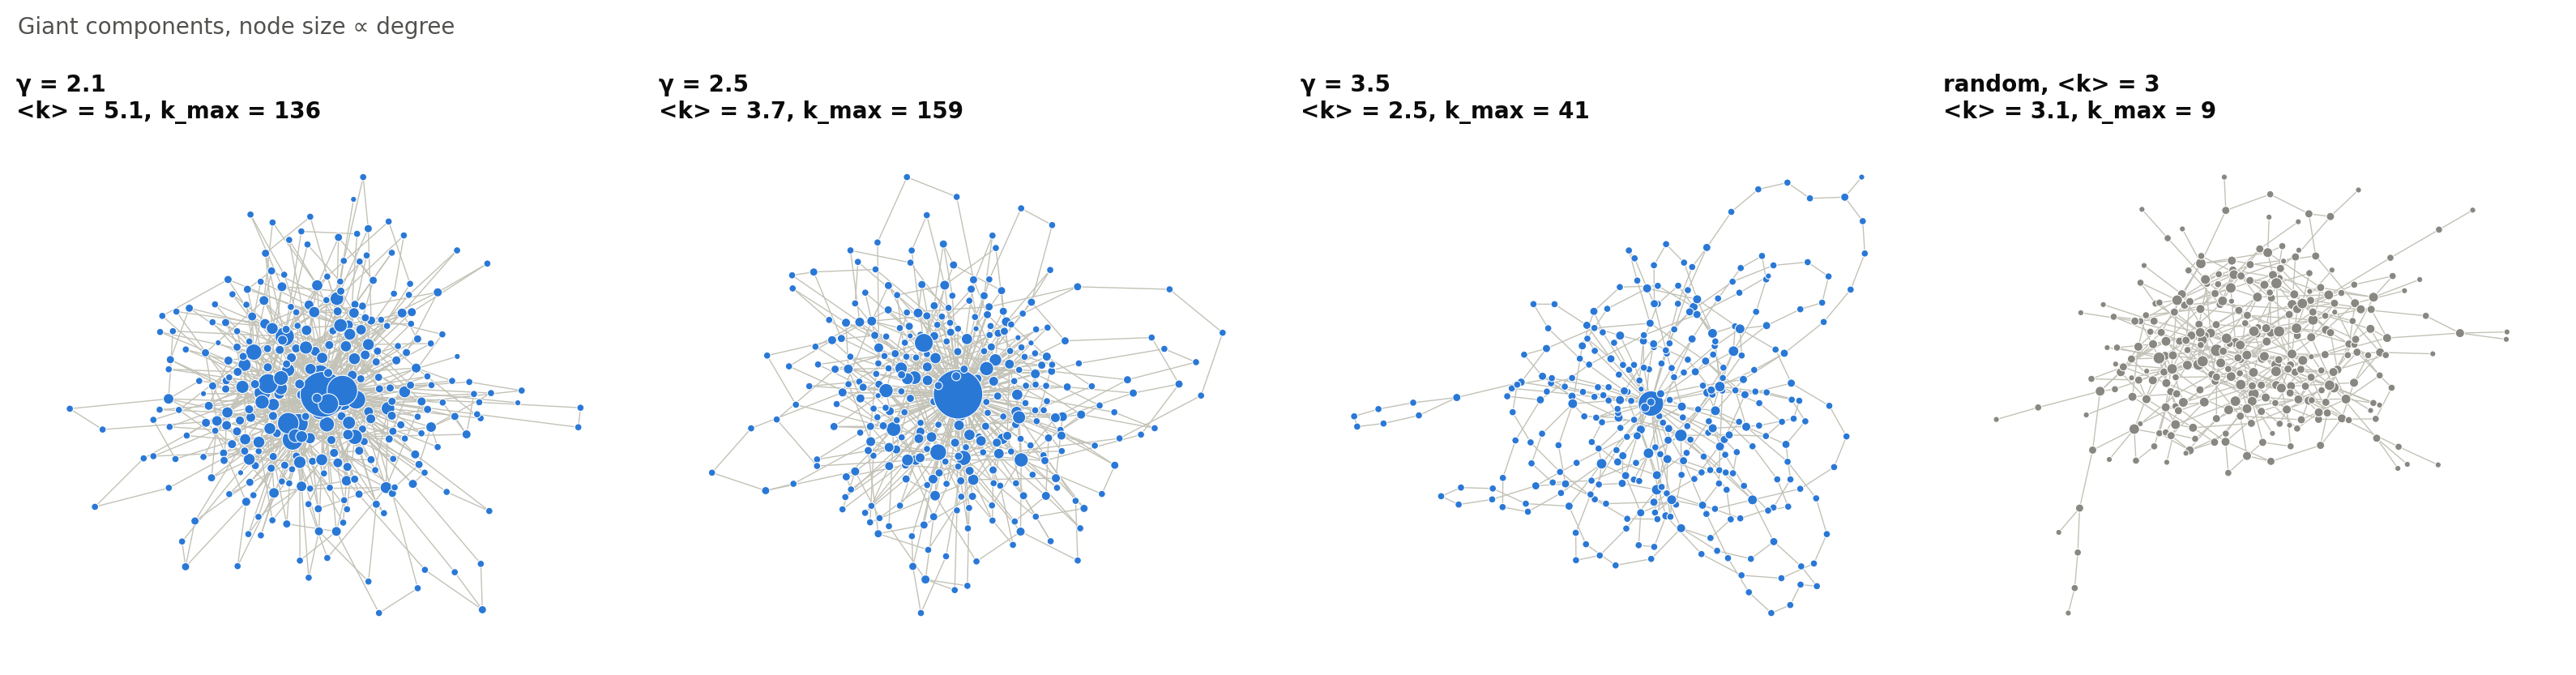

In [36]:
N = 300
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
specs = [("γ = 2.1", 2.1), ("γ = 2.5", 2.5), ("γ = 3.5", 3.5), ("random, <k> = 3", None)]
for ax, (label, g) in zip(axes, specs):
    H = giant(configuration_graph(powerlaw_degree_sequence(N, g, kmin=2, seed=3), seed=3)) if g else \
        giant(nx.fast_gnp_random_graph(N, 3 / (N - 1), seed=3))
    kh = degrees(H)
    hpos = nx.spring_layout(H, seed=SEED, k=1.2 / np.sqrt(H.number_of_nodes()))
    nx.draw_networkx_edges(H, hpos, ax=ax, edge_color=LIGHT, width=0.5)
    nx.draw_networkx_nodes(H, hpos, ax=ax, node_size=4 + 3 * kh, node_color=BLUE if g else MUTED, edgecolors="white", linewidths=0.4)
    ax.set_title(f"{label}\n<k> = {kh.mean():.1f}, k_max = {kh.max()}", fontsize=10); ax.axis("off")
fig.suptitle("Giant components, node size ∝ degree", x=0.01, ha="left", color=INK2, fontsize=10)
plt.tight_layout(); plt.show()

### III.9 Generating networks with a given degree distribution (Section 4.8)
Two ways to build a "random network with the real degree sequence":
* **Configuration model:** give each node $k_i$ stubs and pair the stubs at random. This produces some self-loops and multi-links, which we remove.
* **Degree-preserving randomization:** repeatedly pick two links A–B and C–D and rewire them to A–D and C–B. Every node keeps its degree exactly.

Comparing the real network with these randomized versions tells us **which properties are explained by the degree sequence alone**.

In [37]:
kc = degrees(G)
M = nx.configuration_model(kc, seed=SEED)
G_cm = nx.Graph(M); G_cm.remove_edges_from(nx.selfloop_edges(G_cm))
print(f"Configuration model: {nx.number_of_selfloops(M)} self-loops and "
      f"{M.number_of_edges() - nx.Graph(M).number_of_edges()} multi-links out of {M.number_of_edges():,} links")

t0 = time.time()
G_dpr = G.copy()
nx.double_edge_swap(G_dpr, nswap=2 * G.number_of_edges(), max_tries=10**7, seed=SEED)
print(f"Degree-preserving randomization: {2*G.number_of_edges():,} swaps in {time.time()-t0:.1f} s; "
      f"degrees unchanged: {np.array_equal(degrees(G_dpr), kc)}")

comparison = pd.DataFrame({"real": summary.loc["collaboration (real)"],
                           "degree-preserving": describe(G_dpr),
                           "configuration model": describe(G_cm),
                           "random G(N, L)": summary.loc["random G(N, L)"]}).T
comparison

Configuration model: 12 self-loops and 97 multi-links out of 93,439 links
Degree-preserving randomization: 186,878 swaps in 2.9 s; degrees unchanged: True


,N,L,<k>,<k^2>,k_max,giant comp. N_G/N,<d> (giant comp.),<C>,assortativity r
real,23133.0,93439.0,8.078,178.195,279.0,0.923,5.333,6.334e-01,1.340e-01
degree-preserving,23133.0,93439.0,8.078,178.195,279.0,0.997,4.351,2.445e-03,-1.613e-03
configuration model,23133.0,93330.0,8.069,177.059,278.0,0.999,4.399,2.197e-03,7.111e-04
"random G(N, L)",23133.0,93439.0,8.078,73.380,21.0,1.000,5.048,3.646e-04,-2.212e-03


> **Look for:**
> * By construction, the **degree sequence** alone reproduces $k_{\max}$ and $\langle k^2\rangle$ (the random $G(N,L)$ does not).
> * The randomized networks are even *smaller* than the real one: their $\langle d\rangle$ is shorter than both the real value and the $G(N,L)$ value, because hubs act as shortcuts. In the real network many links are "used up" inside tightly knit groups, which lengthens paths.
> * The degree sequence does **not** explain the clustering: $\langle C\rangle$ collapses by more than two orders of magnitude after randomization. Triangles come from other mechanisms, such as teams of co-authors and communities (Ch 9).
> * It also destroys the **degree correlations**: the collaboration network is *assortative* ($r>0$, hubs link to hubs) and the randomized versions are not (Ch 7).
>
> This "compare with a degree-preserving null model" step is one of the most useful habits in network science.

---
## Part IV: Synthesis and what's next *(about 10 min)*

| Property | Random network (Ch 3) | Scale-free network (Ch 4) | What we measured in the real data |
|---|---|---|---|
| Degree distribution | Poisson, narrow | power law, heavy-tailed | heavy-tailed (power grid excepted) |
| Largest hub | $\sim \ln N$ | $\sim N^{1/(\gamma-1)}$ | hundreds to thousands of links |
| $\langle k^2\rangle$ | $\langle k\rangle(\langle k\rangle+1)$ | grows with $N$ for $\gamma<3$ | $\sigma_k \gg \sqrt{\langle k\rangle}$ |
| Distances | $\ln N/\ln\langle k\rangle$ | $\ln\ln N$ for $2<\gamma<3$ | small world |
| Clustering | $\langle k\rangle/N$, flat in $k$ | (configuration model) low: degrees alone create few triangles | high; decreasing $C(k)$ |
| Giant component | at $\langle k\rangle=1$ | (configuration model) present even for very small $\langle k\rangle$ when $\gamma<3$ (Ch 8) | supercritical |

**Key messages**
1. Random networks are the **null model**: they get the giant component and the small-world property right, and fail on hubs and clustering.
2. Real degree distributions are **heavy-tailed**. Plot them with log-binning or the CCDF, and fit with maximum likelihood, never with least squares on a raw histogram.
3. Heavy tails mean a large $\langle k^2\rangle$ and **no characteristic scale**. This, rather than the exact functional form, drives the consequences in later chapters (robustness in Ch 8, spreading in Ch 10).
4. Degree-preserving randomization separates what the degree sequence explains from what it does not.

**Looking ahead to Ch 5.** Neither the ER model nor the configuration model explains *why* hubs exist; the configuration model simply takes the degree sequence as input. Chapter 5 proposes a mechanism: **growth + preferential attachment** (the Barabási–Albert model), which predicts $\gamma = 3$.

> **Discuss (closing):**
> 1. The power grid is not scale-free. What constraints prevent hubs in it?
> 2. If you had to vaccinate 1% of a population against an epidemic spreading on a scale-free contact network, whom would you choose, and why does $\langle k^2\rangle$ matter?
> 3. The power-law fit for the collaboration network covers only part of the nodes. Is the network "scale-free"? Does the answer change anything in practice?

### Further reading
* A.-L. Barabási, *Network Science*, Ch 2–4 and Advanced Topics 3.A–3.G, 4.A–4.C.
* A. Clauset, C. R. Shalizi, M. E. J. Newman, "Power-law distributions in empirical data", *SIAM Review* 51, 661 (2009).
* J. Alstott, E. Bullmore, D. Plenz, "powerlaw: a Python package for analysis of heavy-tailed distributions", *PLoS ONE* 9, e85777 (2014).
* A. D. Broido, A. Clauset, "Scale-free networks are rare", *Nat. Commun.* 10, 1017 (2019); P. Holme, "Rare and everywhere", *Nat. Commun.* 10, 1016 (2019).